# CARA-T experiment on the Airlines flight-delay stream (Kaggle)

**Research notebook — Cost-Aware Retraining Algorithm, threshold variant (CARA-T)**
Paper: Mahadevan & Mathioudakis, *Cost-aware retraining for machine learning*, Knowledge-Based Systems 293 (2024) 111610.

> **This is an adaptation and operationalisation of CARA within an MLOps workflow, not a line-by-line reproduction of the paper.**
> Cell 3 (**Paper Methodology vs Project Adaptation**) separates what is taken from the paper from what this project adapted (A1–A9).

Scope: **only** the CARA-T research experiment (offline threshold selection → online prequential evaluation → baselines).
No API, database, Docker, monitoring or UI code. Nothing here has been executed for you; numbers appear only when **you** run it in Kaggle.

**Primary result = the retraining-cost (κ) sensitivity sweep (Cells 16–18).** The paper treats κ as an administrator-specified cost and
evaluates CARA over a range of κ; our artifacts contain no such cost model. The detailed single-κ run (Cells 19–22) uses an
**illustrative/project-selected κ** (not paper-defined, not a real-world cost) unless you supply `KAPPA_PRIMARY_ABS` from an external cost model.

| Cells | Content |
|---|---|
| 1–2 | imports, configuration |
| 3 | **Paper Methodology vs Project Adaptation** |
| 4–7 | Phase A: version check, load artifacts, validate 100 batches, inspect, V1 sanity check |
| 8–13 | equations, staleness engine, offline cost matrix, κ grid, offline τ\*/φ\* selection per κ |
| 14–15 | online protocol and runner |
| 16–18 | **PRIMARY RESULT: κ sweep** — `results/kappa_sensitivity.csv` (κ, τ\*, offline cost, #retrains), κ plots, CARA-T vs NR, Markov, Always Retrain, Periodic + retrospective Oracle |
| 19–22 | illustrative single-κ run: per-batch results, model versions V2…, 7 plots, baseline comparison |
| 23–24 | leakage audit, reading guide |

## Cell 1 — Imports

In [23]:
import os, sys, re, json, time, shutil, zipfile, warnings, platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import joblib
import scipy
import scipy.sparse as sp
from scipy.optimize import dual_annealing          # the optimiser named in the paper (Sec. 7.6); used as a cross-check

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

import matplotlib
import matplotlib.pyplot as plt

try:
    display                      # available inside Jupyter / Kaggle
except NameError:                # plain-python fallback
    display = print

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12,
    "axes.labelsize": 10, "legend.frameon": False,
})

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| joblib", joblib.__version__)

python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | scipy 1.16.3 | sklearn 1.6.1 | joblib 1.6.0


## Cell 2 — Configuration

In [24]:
# ----------------------------------------------------------------------------- reproducibility
SEED = 42
np.random.seed(SEED)

# ----------------------------------------------------------------------------- paths (Kaggle only)
KAGGLE_INPUT   = Path("/kaggle/input")
KAGGLE_WORKING = Path("/kaggle/working")
if not (KAGGLE_INPUT.exists() and KAGGLE_WORKING.exists()):
    raise RuntimeError("This notebook is written for Kaggle (/kaggle/input and /kaggle/working were not found).")
WORK_DIR   = KAGGLE_WORKING
MODELS_DIR = WORK_DIR / "models"            # models/v1 (copied, never overwritten), v2, v3, ...
RESULTS_DIR = WORK_DIR / "results"
FIG_DIR    = RESULTS_DIR / "figures"
STREAM_EXTRACT_DIR = WORK_DIR / "stream_extracted"
for _p in (MODELS_DIR, RESULTS_DIR, FIG_DIR):
    _p.mkdir(parents=True, exist_ok=True)
INPUT_SEARCH_ROOTS = [str(KAGGLE_INPUT), str(WORK_DIR)]     # attached dataset(s) first

# ----------------------------------------------------------------------------- data / project design
N_BATCHES   = 100
TARGET      = "Delay"
FEATURES    = ["Airline", "AirportFrom", "AirportTo", "DayOfWeek", "Time", "Length"]
CATEGORICAL = ["Airline", "AirportFrom", "AirportTo", "DayOfWeek"]
NUMERICAL   = ["Time", "Length"]            # 'Flight' is intentionally NOT a feature (same as Model V1)

V1_TRAIN_IDS = list(range(0, 22))           # batches 0-21  : Model V1 training data
HOLDOUT_IDS  = [22, 23, 24]                 # batches 22-24 : Model V1 holdout (NEVER used to tune CARA)
ONLINE_IDS   = list(range(25, 100))         # batches 25-99 : online stream
OFFLINE_IDS  = list(V1_TRAIN_IDS)           # CARA offline phase = historical batches before the online phase that are
                                            # NOT the reserved holdout (adaptation A1)
DECISION_THRESHOLD = 0.5                    # label rule used by Model V1 (metadata.json)

# ----------------------------------------------------------------------------- CARA settings
QUERY_FRACTION = 0.10       # paper Sec. 7.3: queries = random 10% of the points of every batch (query stream "-D")
GAMMA_OVERRIDE = None       # None -> gamma = 1 / (d * Var(X))   (adaptation A4: project choice)

# ----------------------------------------------------------------------------- retraining cost kappa
# The paper treats kappa as an ADMINISTRATOR-SPECIFIED cost (Sec. 4.2) and evaluates CARA over a range of kappa.
# Our artifacts contain NO cost model, so:
#   * the kappa SENSITIVITY SWEEP is the primary result;
#   * KAPPA_PRIMARY_ABS (optional) lets you supply a kappa from your own external cost model (staleness units);
#   * if it is None, the single detailed run uses an ILLUSTRATIVE / PROJECT-SELECTED kappa: KAPPA_DEFAULT_MULT x a
#     "reference scale" = median positive offline relative staleness. This is NOT paper-defined, NOT a measured or
#     real-world (monetary) cost, and carries no exchange-rate meaning; it only places the grid in a numerically sensible range.
KAPPA_PRIMARY_ABS = None                                     # e.g. 40.0 once you have an external cost model
KAPPA_DEFAULT_MULT = 1.0
KAPPA_SWEEP_MULTS = [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64]     # multiples of the reference scale (ignored if ABS grid given)
KAPPA_SWEEP_ABS   = None                                     # optional explicit grid in staleness units, e.g. [5, 10, 20, 50, 100, 200]

RUN_ONLINE_ORACLE = True    # retrospective Oracle (paper Sec. 6): needs ~75x75/2 extra model evaluations (a few minutes)

# ----------------------------------------------------------------------------- misc
SIM_CHUNK_ROWS     = 20000   # rows of D processed at once when building the RBF kernel
SAVE_MODEL_COMPRESS = 3
REPRO_TOL          = 1e-3    # tolerance for the "V1 reproduces metadata holdout metrics" sanity check
print("WORK_DIR   :", WORK_DIR)
print("Phases     : V1-train/offline", V1_TRAIN_IDS[0], "-", V1_TRAIN_IDS[-1],
      "| holdout", HOLDOUT_IDS, "| online", ONLINE_IDS[0], "-", ONLINE_IDS[-1])

WORK_DIR   : /kaggle/working
Phases     : V1-train/offline 0 - 21 | holdout [22, 23, 24] | online 25 - 99


## Cell 3 — Paper Methodology vs Project Adaptation

> **This is an adaptation and operationalisation of CARA within an MLOps workflow, not a line-by-line reproduction of the paper.**

### 3.1 Directly taken from the paper (equation numbers are the paper's)
| Element | Where in the paper | How it is used here |
|---|---|---|
| **CARA concept** — cost-aware `Keep`/`Retrain` decision balancing staleness against retraining cost | Sec. 1, 5 | the retraining-decision component studied in this notebook |
| **Staleness formulation** — similarity(query, data point) × 0-1 model loss; RBF similarity | Eq. 1–3, 15–16 | `psi()` and `relative_staleness()` (Cell 9) |
| **Retraining cost κ** — expressed in staleness units, **specified by the system administrator** | Sec. 4.2, 7 | varied over a grid (sensitivity sweep); see A3 |
| **Cost matrix** and **strategy cost** | Eq. 4–6 | `build_cost_matrix()` (Cell 11), strategy cost accounting in `run_online()` |
| **CARA-T threshold decision** — `Keep` iff Ψ̄ < τ | Eq. 8 | the decision rule of the method under study |
| **Offline parameter optimisation** — τ\* = argmin of the offline strategy cost | Eq. 7, Sec. 4.4, 5, 7.6 | exhaustive plateau search per κ (Cell 12) |
| **Online prequential (test-then-train) evaluation** | Alg. 1, Sec. 7.5 | batch *t* is answered by the deployed model **first**; a new model serves from *t*+1 |
| **Retraining from scratch** on the current batch only | Sec. 3, Alg. 1, App. E | `RETRAIN` at *t* ⇒ new pipeline fit on $D_t$ only |
| **Oracle** — retrospective dynamic-programming optimum (a lower bound) | Sec. 6, Eq. 11–14 | Cell 17 |
| **Relevant baselines** — NR (Never Retrain), Markov, Oracle | Sec. 7.4, Eq. 17 | Cells 16–17 |
| **κ is varied** over a range in all real-world experiments | Sec. 8, Figs. 4–7 | the κ sensitivity sweep is the primary result |

### 3.2 Adapted for this project (nothing is changed silently)
| Topic | Paper | This project |
|---|---|---|
| Starting model | trained inside the experiment | **Model V1 is already trained on batches 0–21** (hyper-parameter selection in the previous notebook: 0–17 train / 18–21 validation; final fit on 0–21), RandomForest pipeline, never modified |
| Hold-out | none | **Batches 22–24 are an untouched Model V1 holdout** and are never used for CARA tuning |
| Offline phase | 25 batches | batches 0–21 (22 batches) |
| Online stream | batches 26–100 (75 batches) | **batches 25–99** (75 batches, file order, never shuffled) |
| Feature representation | Airlines with $d=7198$ (flight number one-hot encoded) | **`Flight` is excluded** (identifier-like, very high cardinality) ⇒ far fewer encoded features than the paper's Airlines setup (the exact $d$ is printed in Cell 9) |
| Similarity space / preprocessing | not specified exactly | one-hot categoricals + z-scored numerics (encoder fit on batches 0–21), $\gamma=1/(d\cdot\mathrm{Var}(X_{ref}))$, unseen categories ⇒ zero vector (A4) |
| Query sampling | random 10% of each batch | **seeded** random 10% per batch, seed = `(SEED, batch_id)` (A6) |
| Retraining cost κ | administrator-specified | **no external cost model exists** ⇒ κ sweep (primary); the single demonstration run uses an *illustrative/project-selected κ* (A3) |
| τ optimiser | grid search / dual annealing | exact exhaustive plateau search; `dual_annealing` only as a cross-check (A5) |
| Periodic baseline | CARA-P (period φ and offset a) | simplified, offset not searched (A7) |
| Seeds | 5 seeds averaged | **one** seed |
| Baselines not implemented | ADWIN, DDM, CARA-CT, CARA-P | not implemented (the periodic rule is a paper-inspired project baseline) |

### 3.3 How our 100-batch stream maps to the paper
| Paper | Our project |
|---|---|
| batches $D_t$, $t=0..99$ | `batch_000.csv … batch_099.csv`, order preserved, never shuffled |
| $T_{offline}$ | **batches 0–21** |
| online phase | **batches 25–99** (75 batches) |
| initial model | **Model V1** (supplied, never modified) |
| model $M_{t'}$ after a retrain at $t$ | new pipeline with V1's hyper-parameters, fit on $D_t$ only → V2, V3, … |
| queries $Q_t$ | seeded random 10% of the rows of batch $t$ |

### 3.4 Four different activities — kept strictly separate
| Activity | Batches | Used for | May influence CARA parameters? |
|---|---|---|---|
| **Model V1 training** | 0–21 | done in the previous notebook | – |
| **CARA offline parameter selection** | 0–21 | offline cost matrix → τ\*(κ) (and φ\*, γ, similarity encoder) | yes — its purpose |
| **V1 holdout evaluation** | 22–24 | *read-only* check that the loaded V1 reproduces `metadata.json` | **no** |
| **Online evaluation** | 25–99 | prequential test-then-train; batch $t$ is trained on only **after** it was predicted | **no** (τ\* frozen) |

The offline cost matrix needs **fresh single-batch models** $M_{t'}$, so Model V1 is not involved in choosing τ\*; using batches 0–21 offline neither touches the holdout nor alters V1.

### 3.5 Adaptation details A1–A9
* **A1 – Offline window.** Paper: 25 offline batches. Ours: batches 0–21, because 22–24 are an untouched Model V1 holdout. The online phase starts at batch 25 (a 3-batch gap the paper does not have).
* **A2 – Starting model.** The supplied **V1 is trained on batches 0–21**, whereas every **CARA-retrained model uses only the current batch** (paper rule). For V1 the "training data" $D_{t'}$ in Eq. 3 is the concatenation of batches 0–21 (`REF`). τ\* is learned from single-batch models but also applied to V1 at the first online batches — a calibration mismatch we flag, not hide.
* **A3 – Retraining cost κ (declared, not derived from the paper).** κ is administrator-specified in the paper (staleness units); we have no external cost model. Therefore **the κ sweep is the primary result**. The sweep grid is a set of multiples of a *project-convenience reference scale* (median positive offline Ψ̄). For the single demonstration run: `KAPPA_PRIMARY_ABS` if you supply one from an external cost model, otherwise an **illustrative/project-selected κ** (= `KAPPA_DEFAULT_MULT` × the reference scale). That κ is **not paper-defined** and **not a real-world (monetary) cost or exchange rate**; it only makes the grid numerically sensible. Measured training seconds are recorded as a separate, unconverted resource metric.
* **A4 – Similarity space and γ (project adaptation).** The paper gives no exact formula or scaling. We use one-hot categoricals + z-scored numerics (encoder fit on batches 0–21) and $\gamma=1/(d\cdot\mathrm{Var}(X_{ref}))$. Unseen categories map to the zero vector.
* **A5 – Optimiser for Eq. 7.** CARA-T's cost depends on τ only through $\overline\Psi<\tau$, hence is piecewise-constant. We evaluate **every** distinct plateau (exact; the paper allows grid search), take the **midpoint** of the optimal plateau; ties → fewer retrains, then larger τ. `dual_annealing` (the paper's optimiser) is a cross-check.
* **A6 – Queries.** Seeded random 10% sample of every batch, seed = `(SEED, batch_id)`, so the sample of batch $t$ depends on no other batch.
* **A7 – Periodic baseline.** Paper-inspired (CARA-P, Eq. 10): retrain when $k>0$ and $k \bmod\phi=0$; the unsearched offset $a$ is simplified; φ\* by offline linear search over the **complete range $[1, T_{offline}]$** (Sec. 7.6; here $\phi=1..22$).
* **A8 – Cost accounting.** Following Eq. 4–6, a batch where `Retrain` is decided is charged κ, a `Keep` batch $\overline\Psi_{t,t'}$. The retrain batch's queries are still answered by the *old* model (prequential). The supplied V1 is not charged online. (Offline, the initial training at batch 0 is charged one κ, as in Eq. 4; the offline retrain *count* excludes it.)
* **A9 – Oracle.** Computed by dynamic programming (Eq. 12–14) over the online stream **retrospectively**, using all online labels, starting from V1 (uncharged). It is a lower bound for comparison; it is **not deployable** in a real online system, it is **not part of the deployable MLOps pipeline**, and no online decision ever uses it.

### 3.6 Baselines — which are the paper's and which are ours
| Strategy | Definition | Status |
|---|---|---|
| **CARA-T** | `Keep` iff Ψ̄ < τ\*(κ), τ\* learned offline | the method under study (paper Sec. 5.1, adapted) |
| **NR = Never Retrain** | always keep the current model (V1 forever) | paper baseline (Sec. 7.4) |
| **Always Retrain** | retrain after every online batch | *additional project baseline* (the paper's Appendix E uses it, but it is not in the Sec. 7.4 baseline set) |
| **Periodic** | retrain every φ\* batches | *project baseline inspired by the paper's CARA-P* (A7) |
| **Markov** | `Keep` iff Ψ̄ < κ (Eq. 17) | paper baseline (Sec. 7.4) |
| **Oracle** | retrospectively optimal strategy (DP) | paper's lower bound (Sec. 6) — uses future information, **not deployable** |
| ADWIN, DDM, CARA-CT | – | **not implemented** here |

**Not used by CARA:** `reference_data.json`, PSI/KS-style monitoring statistics, accuracy thresholds, and the `Flight` column. Monitoring answers *"what changed?"*; CARA-T answers *"should the deployed model be replaced?"* — they are separate concepts and monitoring never triggers a retrain here. We make **no drift claims**.


## Cell 4 — Phase A: locate artifacts, VERIFY the scikit-learn version, then load

In [25]:
BATCH_RE = re.compile(r"^batch_(\d+)\.csv$")

def find_all(root, predicate):
    root = Path(root); hits = []
    if not root.exists():
        return hits
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in {".git", "__pycache__", ".ipynb_checkpoints", "__MACOSX"}]
        for f in filenames:
            if predicate(f):
                hits.append(Path(dirpath) / f)
    return hits

def _is_later_version_path(p):
    return re.search(r"/v([2-9]|\d{2,})/", str(p).replace("\\", "/")) is not None

def discover_batches():
    for root in INPUT_SEARCH_ROOTS:
        files = find_all(root, lambda f: BATCH_RE.match(f) is not None)
        if not files:
            for z in find_all(root, lambda f: f.lower().endswith(".zip")):
                try:
                    with zipfile.ZipFile(z) as zf:
                        if any(BATCH_RE.match(Path(n).name) for n in zf.namelist()):
                            target = STREAM_EXTRACT_DIR / z.stem
                            if not target.exists():
                                print(f"Extracting {z} -> {target}")
                                zf.extractall(target)
                except zipfile.BadZipFile:
                    print("Skipping unreadable zip:", z)
            files = find_all(STREAM_EXTRACT_DIR, lambda f: BATCH_RE.match(f) is not None)
        if files:
            groups = {}
            for f in files:
                groups.setdefault(f.parent, []).append(f)
            best = max(groups, key=lambda p: len(groups[p]))
            return best, sorted(groups[best])
    raise FileNotFoundError("No batch_*.csv (or zip containing them) found under: " + ", ".join(INPUT_SEARCH_ROOTS))

def pick_file(filename, must_have_keys=None, required=True):
    for root in INPUT_SEARCH_ROOTS:
        cands = [p for p in find_all(root, lambda f: f == filename) if not _is_later_version_path(p)]
        cands.sort(key=lambda p: ("/v1/" not in str(p).replace("\\", "/"), len(str(p))))
        for p in cands:
            if must_have_keys:
                try:
                    with open(p) as fh:
                        _j = json.load(fh)
                    if not all(k in _j for k in must_have_keys):
                        continue
                except Exception:
                    continue
            return p
    if required:
        raise FileNotFoundError(f"Required file '{filename}' not found under: {INPUT_SEARCH_ROOTS}")
    print(f"[warn] optional file '{filename}' not found")
    return None

BATCH_DIR, BATCH_FILES = discover_batches()
MODEL_SRC = pick_file("model_pipeline.joblib")
META_SRC  = pick_file("metadata.json", must_have_keys=["feature_columns", "metrics"])
REF_SRC   = pick_file("reference_data.json", required=False)
print("batch dir :", BATCH_DIR, f"({len(BATCH_FILES)} files)")
print("model     :", MODEL_SRC)
print("metadata  :", META_SRC)
print("reference :", REF_SRC)

# ------------------------------------------------------------------------------------------------------------
# HARD VERSION GATE: runs BEFORE joblib.load. metadata.json is read as-is and is never edited.
# Unpickling a scikit-learn pipeline under a different scikit-learn version can fail or, worse, silently change behaviour.
# ------------------------------------------------------------------------------------------------------------
with open(META_SRC) as fh:
    _META_PRE = json.load(fh)
REQUIRED_SKLEARN = _META_PRE.get("sklearn_version")
if not REQUIRED_SKLEARN:
    raise RuntimeError("metadata.json has no 'sklearn_version'; cannot verify that model_pipeline.joblib is loadable.")
if sklearn.__version__ != REQUIRED_SKLEARN:
    raise RuntimeError(
        "\n" + "=" * 90 +
        f"\nINCOMPATIBLE scikit-learn: model_pipeline.joblib was saved with scikit-learn {REQUIRED_SKLEARN} "
        f"(metadata.json), but this Kaggle session runs {sklearn.__version__}."
        "\nThe model was NOT loaded. Do not edit metadata.json to hide this."
        f"\nFix: in a first cell run   !pip install -q scikit-learn=={REQUIRED_SKLEARN}   then restart the session "
        "(Run > Restart session) and run the notebook again from Cell 1.\n" + "=" * 90)
print(f"scikit-learn {sklearn.__version__} == metadata.json sklearn_version -> OK to load.")

# --- Model V1 is COPIED to models/v1 (never modified / overwritten) ---
V1_DIR = MODELS_DIR / "v1"
V1_DIR.mkdir(parents=True, exist_ok=True)
for src, name in [(MODEL_SRC, "model_pipeline.joblib"), (META_SRC, "metadata.json"), (REF_SRC, "reference_data.json")]:
    if src is None:
        continue
    dst = V1_DIR / name
    if not dst.exists():
        shutil.copy2(src, dst)
    elif dst.stat().st_size != Path(src).stat().st_size:
        raise RuntimeError(f"{dst} differs from the input artifact {src}. models/v1 is never overwritten; "
                           "remove the stale copy manually if you really intend to start from a different V1.")

with open(V1_DIR / "metadata.json") as fh:
    META = json.load(fh)
try:
    PIPE_V1 = joblib.load(V1_DIR / "model_pipeline.joblib")
except Exception as _e:                     # e.g. numpy/scipy/sklearn binary incompatibility while unpickling
    raise RuntimeError(
        "\n" + "=" * 90 +
        f"\nmodel_pipeline.joblib could not be unpickled in this runtime ({type(_e).__name__}: {_e})."
        f"\nIt was saved with scikit-learn {REQUIRED_SKLEARN}"
        f" (numpy {META.get('numpy_version')}, scipy {META.get('scipy_version')}, joblib {META.get('joblib_version')} per metadata.json);"
        f" this session has scikit-learn {sklearn.__version__}, numpy {np.__version__}, scipy {scipy.__version__}, joblib {joblib.__version__}."
        "\nModel V1 was NOT altered and metadata.json was NOT edited. Install the matching library versions, "
        "restart the session and re-run from Cell 1.\n" + "=" * 90) from _e
REFERENCE_DATA = None
if (V1_DIR / "reference_data.json").exists():
    with open(V1_DIR / "reference_data.json") as fh:
        REFERENCE_DATA = json.load(fh)

print("\nModel V1:", META.get("model_type"))
print("Pipeline steps:", [n for n, _ in PIPE_V1.steps])
print("Reference data keys:", list(REFERENCE_DATA.keys()) if REFERENCE_DATA else None)

for lib, cur in [("pandas_version", pd.__version__), ("numpy_version", np.__version__), ("joblib_version", joblib.__version__), ("scipy_version", scipy.__version__)]:
    if META.get(lib) and META[lib] != cur:
        print(f"[warn] {lib}: model was saved with {META[lib]}, running {cur} (scikit-learn matches, so loading is allowed; "
              "Cell 7 re-checks that V1 reproduces its stored holdout metrics)")

assert META["feature_columns"] == FEATURES, "feature list differs from metadata.json"
assert META["categorical_features"] == CATEGORICAL and META["numerical_features"] == NUMERICAL
assert META["training_batch_ids"] == V1_TRAIN_IDS, "V1 training batches differ from metadata.json"
assert META["holdout_batch_ids"] == HOLDOUT_IDS, "holdout batches differ from metadata.json"
assert HOLDOUT_IDS[-1] + 1 == ONLINE_IDS[0] and ONLINE_IDS[-1] == N_BATCHES - 1
print("\nPhase design matches metadata.json.")

batch dir : /kaggle/working/stream (100 files)
model     : /kaggle/working/models/v1/model_pipeline.joblib
metadata  : /kaggle/working/models/v1/metadata.json
reference : /kaggle/working/models/v1/reference_data.json
scikit-learn 1.6.1 == metadata.json sklearn_version -> OK to load.

Model V1: Pipeline(ColumnTransformer[OneHotEncoder(handle_unknown='ignore') + passthrough] -> RandomForestClassifier)
Pipeline steps: ['preprocess', 'rf']
Reference data keys: ['model_version', 'source', 'training_batch_ids', 'n_samples', 'target', 'numerical_features', 'categorical_features']

Phase design matches metadata.json.


## Cell 5 — Validate the 100 batches (existence, order, columns, target, malformed rows)

In [26]:
ids_found = [int(BATCH_RE.match(p.name).group(1)) for p in BATCH_FILES]
errors, warns_ = [], []

dup = sorted({i for i in ids_found if ids_found.count(i) > 1})
missing = sorted(set(range(N_BATCHES)) - set(ids_found))
extra = sorted(set(ids_found) - set(range(N_BATCHES)))
if dup:     errors.append(f"duplicate batch ids: {dup}")
if missing: errors.append(f"missing batch ids: {missing}")
if extra:   errors.append(f"unexpected batch ids: {extra}")

# Batch order is defined by the numeric id in the file name (NOT by lexicographic glob order, NOT by shuffling).
path_by_id = {i: p for i, p in zip(ids_found, BATCH_FILES)}

BATCHES = {}
REQUIRED_COLS = FEATURES + [TARGET]
for b in range(N_BATCHES):
    if b not in path_by_id:
        continue
    try:
        df = pd.read_csv(path_by_id[b])
    except Exception as e:                                   # malformed csv
        errors.append(f"batch {b}: cannot be read ({e})"); continue
    miss_cols = [c for c in REQUIRED_COLS if c not in df.columns]
    if miss_cols:
        errors.append(f"batch {b}: missing columns {miss_cols}"); continue
    if len(df) == 0:
        errors.append(f"batch {b}: empty"); continue
    n_nan = int(df[REQUIRED_COLS].isna().sum().sum())
    if n_nan:
        errors.append(f"batch {b}: {n_nan} missing values in feature/target columns"); continue
    for c in NUMERICAL + [TARGET]:
        if not pd.api.types.is_numeric_dtype(df[c]):
            errors.append(f"batch {b}: column {c} is not numeric"); break
    else:
        bad_target = sorted(set(df[TARGET].unique()) - {0, 1})
        if bad_target:
            errors.append(f"batch {b}: target has values outside {{0,1}}: {bad_target}"); continue
        df[TARGET] = df[TARGET].astype(int)
        BATCHES[b] = df.reset_index(drop=True)               # row order inside the batch is preserved

if errors:
    raise RuntimeError("Batch validation failed:\n  - " + "\n  - ".join(errors))

# consistency with metadata.json
n_train = sum(len(BATCHES[b]) for b in V1_TRAIN_IDS)
n_hold  = sum(len(BATCHES[b]) for b in HOLDOUT_IDS)
for label, got, exp in [("n_training_samples", n_train, META["n_training_samples"]),
                        ("n_holdout_samples", n_hold, META["n_holdout_samples"])]:
    flag = "OK " if got == exp else "MISMATCH"
    print(f"{flag} {label}: batches give {got:,} | metadata.json says {exp:,}")
    if got != exp:
        warns_.append(label)

print(f"\nAll {len(BATCHES)} batches present (ids 0..{N_BATCHES-1}), columns/targets valid, no NaNs.")
print("Note: the CSVs contain no timestamp, so temporal order can only be validated by the file index.")
print("Batch sizes: min", min(len(v) for v in BATCHES.values()), "| max", max(len(v) for v in BATCHES.values()),
      "| total", f"{sum(len(v) for v in BATCHES.values()):,}")

OK  n_training_samples: batches give 118,668 | metadata.json says 118,668
OK  n_holdout_samples: batches give 16,182 | metadata.json says 16,182

All 100 batches present (ids 0..99), columns/targets valid, no NaNs.
Note: the CSVs contain no timestamp, so temporal order can only be validated by the file index.
Batch sizes: min 5393 | max 5394 | total 539,383


## Cell 6 — Inspect the stream (descriptive only; no drift claims)

First / last batches:


,batch_id,phase,n_rows,n_delayed,n_on_time,delay_rate
0,0,V1 train / CARA offline,5394,1814,3580,0.3363
1,1,V1 train / CARA offline,5394,2712,2682,0.5028
2,2,V1 train / CARA offline,5394,2818,2576,0.5224
97,97,online,5393,2181,3212,0.4044
98,98,online,5393,2890,2503,0.5359
99,99,online,5393,3022,2371,0.5604



Per phase:


,n_batches,n_rows,mean_delay_rate,min_delay_rate,max_delay_rate
phase,,,,,
V1 train / CARA offline,22,118668,0.3469,0.2088,0.5224
V1 holdout,3,16182,0.2851,0.1906,0.3767
online,75,404533,0.4808,0.2710,0.6628


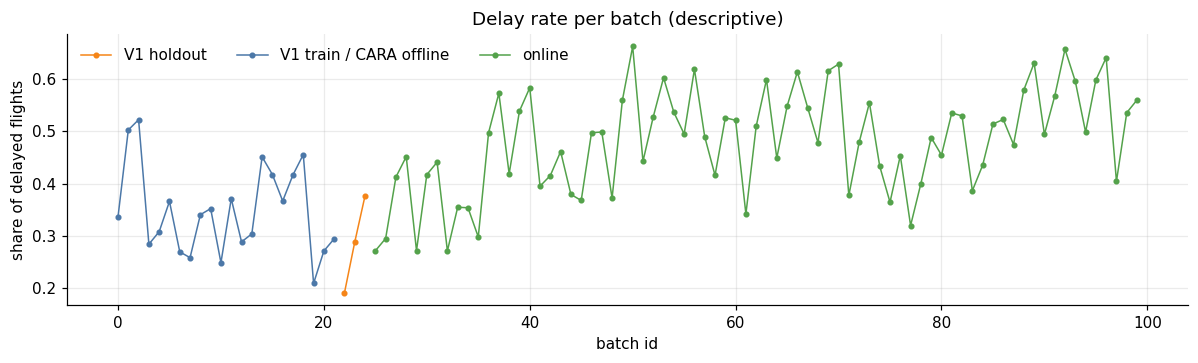

In [27]:
def phase_of(b):
    if b in V1_TRAIN_IDS: return "V1 train / CARA offline"
    if b in HOLDOUT_IDS:  return "V1 holdout"
    return "online"

rows = []
for b in range(N_BATCHES):
    y = BATCHES[b][TARGET]
    rows.append(dict(batch_id=b, phase=phase_of(b), n_rows=len(y), n_delayed=int(y.sum()),
                     n_on_time=int((1 - y).sum()), delay_rate=float(y.mean())))
STREAM_SUMMARY = pd.DataFrame(rows)

print("First / last batches:")
display(pd.concat([STREAM_SUMMARY.head(3), STREAM_SUMMARY.tail(3)]))
print("\nPer phase:")
display(STREAM_SUMMARY.groupby("phase", sort=False).agg(
    n_batches=("batch_id", "count"), n_rows=("n_rows", "sum"),
    mean_delay_rate=("delay_rate", "mean"), min_delay_rate=("delay_rate", "min"), max_delay_rate=("delay_rate", "max")))

fig, ax = plt.subplots(figsize=(11, 3.4))
colors = {"V1 train / CARA offline": "#4C78A8", "V1 holdout": "#F58518", "online": "#54A24B"}
for ph, g in STREAM_SUMMARY.groupby("phase"):
    ax.plot(g["batch_id"], g["delay_rate"], "o-", ms=3, lw=1, color=colors[ph], label=ph)
ax.set_xlabel("batch id"); ax.set_ylabel("share of delayed flights"); ax.set_title("Delay rate per batch (descriptive)")
ax.legend(ncol=3); plt.tight_layout(); plt.show()

## Cell 7 — Prepare inputs exactly as Model V1 expects, and sanity-check V1 against `metadata.json`

In [28]:
PRE_V1 = PIPE_V1.steps[0][1]            # ColumnTransformer
CLF_V1 = PIPE_V1.steps[-1][1]           # RandomForestClassifier
assert hasattr(PRE_V1, "transformers_"), "first pipeline step is expected to be a fitted ColumnTransformer"

def _unwrap(t):
    return t.steps[-1][1] if hasattr(t, "steps") else t

# Read the dtype of the categories V1's OneHotEncoder was fitted with. handle_unknown='ignore' would SILENTLY
# produce all-zero rows if we fed e.g. str where V1 saw int, so we cast to V1's dtype explicitly.
CAT_CAST, V1_CATEGORIES = {}, {}
for _name, _trans, _cols in PRE_V1.transformers_:
    _t = _unwrap(_trans)
    if isinstance(_t, OneHotEncoder):
        for _c, _cats in zip(_cols, _t.categories_):
            V1_CATEGORIES[_c] = set(_cats.tolist())
            CAT_CAST[_c] = "str" if _cats.dtype.kind in "OUS" else "num"
print("V1 categorical dtypes:", CAT_CAST)
if not CAT_CAST:
    print("[warn] could not read OneHotEncoder categories; inputs are passed through uncast")

def prep_X(df):
    """Feature frame in V1's expected column order and dtypes ('Flight', 'Delay' dropped)."""
    X = df[FEATURES].copy()
    for c in CATEGORICAL:
        if CAT_CAST.get(c) == "str":   X[c] = X[c].astype(str)
        elif CAT_CAST.get(c) == "num": X[c] = pd.to_numeric(X[c])
    for c in NUMERICAL:
        X[c] = pd.to_numeric(X[c])
    return X

def batch_metrics(y, pred, proba):
    """Classification metrics for one batch. ROC-AUC only when both classes are present."""
    out = dict(accuracy=float(accuracy_score(y, pred)),
               precision=float(precision_score(y, pred, zero_division=0)),
               recall=float(recall_score(y, pred, zero_division=0)),
               f1=float(f1_score(y, pred, zero_division=0)), roc_auc=np.nan)
    if len(np.unique(y)) == 2:
        try:
            out["roc_auc"] = float(roc_auc_score(y, proba))
        except ValueError:
            pass
    return out

# ---- read-only sanity check on the V1 holdout (batches 22-24): evaluation only, NOTHING is tuned on it ----
hold = pd.concat([BATCHES[b] for b in HOLDOUT_IDS], ignore_index=True)
_P = PIPE_V1.predict_proba(prep_X(hold))
_cls = list(PIPE_V1.classes_)
_pred = np.asarray(PIPE_V1.classes_)[np.argmax(_P, axis=1)].astype(int)
repro = batch_metrics(hold[TARGET].values, _pred, _P[:, _cls.index(1)])
print("\nV1 on holdout 22-24  (recomputed here vs metadata.json):")
for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    diff = repro[k] - META["metrics"][k]
    print(f"  {k:9s} recomputed={repro[k]:.4f}  metadata={META['metrics'][k]:.4f}  diff={diff:+.5f}")
if max(abs(repro[k] - META["metrics"][k]) for k in ["accuracy", "f1", "roc_auc"]) > REPRO_TOL:
    print("[WARN] V1 does not reproduce the stored holdout metrics -> check library versions / dtype casting above "
          "BEFORE trusting any downstream number.")
else:
    print("V1 reproduces the stored holdout metrics within tolerance.")
V1_HOLDOUT_ACC = META["metrics"]["accuracy"]

# ---- unseen categorical values (handled by handle_unknown='ignore'; reported for transparency) ----
rows = []
for b in range(N_BATCHES):
    X = prep_X(BATCHES[b])
    unseen_any = np.zeros(len(X), dtype=bool)
    for c in CATEGORICAL:
        if c in V1_CATEGORIES:
            unseen_any |= ~X[c].isin(V1_CATEGORIES[c]).values
    rows.append(dict(batch_id=b, share_rows_with_unseen_category=float(unseen_any.mean())))
UNSEEN = pd.DataFrame(rows)
_on = UNSEEN[UNSEEN.batch_id.isin(ONLINE_IDS)]
print(f"\nRows with a category unseen by V1 -- online batches: mean {_on.share_rows_with_unseen_category.mean():.4%}, "
      f"max {_on.share_rows_with_unseen_category.max():.4%}  (encoded as all-zero one-hot, no crash)")

V1 categorical dtypes: {'Airline': 'num', 'AirportFrom': 'num', 'AirportTo': 'num', 'DayOfWeek': 'num'}

V1 on holdout 22-24  (recomputed here vs metadata.json):
  accuracy  recomputed=0.7002  metadata=0.7002  diff=+0.00000
  precision recomputed=0.4697  metadata=0.4697  diff=+0.00000
  recall    recomputed=0.3993  metadata=0.3993  diff=+0.00000
  f1        recomputed=0.4316  metadata=0.4316  diff=+0.00000
  roc_auc   recomputed=0.6787  metadata=0.6787  diff=+0.00000
V1 reproduces the stored holdout metrics within tolerance.

Rows with a category unseen by V1 -- online batches: mean 0.0262%, max 0.1112%  (encoded as all-zero one-hot, no crash)


## Cell 8 — Equations used (paper notation) and what every term means

**Similarity and loss (Sec. 7, Eq. 15–16)**
$$\mathrm{sim}(q,x)=\exp\!\big(-\gamma\,\lVert q-x\rVert^{2}\big),\qquad \ell(M,x,y)=\mathbb I\big(M(x)\neq y\big)$$
$\gamma$: inverse-variance length scale (our concrete choice: adaptation A4); $\mathbb I$: indicator, i.e. 0-1 loss.

**Staleness of one query (Eq. 1)**
$$\psi(q,D,M)=\frac1{|D|}\sum_{(x,y)\in D}\mathrm{sim}(q,x)\cdot \ell(M,x,y)$$

**Absolute staleness of a query batch (Eq. 2)**
$$\Psi(Q_t,D_{t_2},M_{t_3})=\sum_{q\in Q_t}\psi(q,D_{t_2},M_{t_3})\;=\;\frac1{|D_{t_2}|}\sum_{x\in D_{t_2}} w_t(x)\,\ell(M_{t_3},x,y),\quad w_t(x)=\sum_{q\in Q_t}\mathrm{sim}(q,x)$$
(the right-hand form is algebraically identical and is what the code evaluates.)

**Relative staleness — the quantity CARA-T thresholds (Eq. 3)**
$$\overline\Psi_{t,t'}=\Psi(Q_t,D_t,M_{t'})-\Psi(Q_t,D_{t'},M_{t'})$$
$t$: current batch; $t'$: batch at which the deployed model was trained; second term: the model's loss on its **own training data**. $\overline\Psi_{t,t}=0$.

**Cost matrix (Eq. 4), strategy and strategy cost (Eq. 5–6)**
$$C[t',t]=\begin{cases}\overline\Psi_{t,t'}&t'<t\;(\text{Keep})\\ \kappa_t&t'=t\;(\text{Retrain})\\ \infty&\text{otherwise}\end{cases}\qquad S=(s_0,\dots,s_T),\quad \mathrm{cost}(S)=\sum_{t=0}^{T}C[s_t,t]$$
$s_t$: batch at which the model used at $t$ was trained ($s_t=t$ ⇔ Retrain). $\kappa_t=\kappa$: retraining cost in staleness units (administrator-specified in the paper).

**CARA-T (Eq. 8) and its offline optimisation (Eq. 7)**
$$\mathcal R(t,t',\{\tau\})=\begin{cases}\texttt{Keep}&\overline\Psi_{t,t'}<\tau\\ \texttt{Retrain}&\text{otherwise}\end{cases}\qquad \tau^*=\arg\min_{\tau}\ \mathrm{cost}\big(S_\tau\big)\ \ (\text{Algorithm 1 on batches }0..T_{offline})$$

**Markov baseline (Eq. 17)** — an uncalibrated CARA-T whose threshold is the retraining cost itself:
$$\mathcal R(t,t')=\begin{cases}\texttt{Keep}&\overline\Psi_{t,t'}<\kappa_t\\ \texttt{Retrain}&\text{otherwise}\end{cases}$$

**Oracle (Eq. 11–14)** — retrospective dynamic programme over a *complete* cost matrix; it needs all future batches and is therefore not implementable online:
$$v^*(t)=\min_{p\in[0,t]}\Big(\sum_{t'=p}^{t}C[p,t']+v^*(p-1)\Big),\qquad v^*(-1)=0,\qquad \mathcal R(t,t',\{O\})=\texttt{Retrain}\iff t\in O$$

**Metrics.** *Prediction performance* = accuracy/precision/recall/F1/AUC of the deployed model on the batch (and the paper's "query accuracy" on $Q_t$). *Staleness* = $\overline\Psi_{t,t'}$. *Retraining cost* = κ (staleness units) plus measured seconds. *Strategy cost* = Eq. 6. *SCPE* = $100\,|b-a|/|b|$ with $b$ the Oracle cost and $a$ the strategy cost. These are never mixed.

## Cell 9 — Staleness engine: similarity space, RBF kernel, queries, caches (Eq. 1–3)

In [29]:
# ---------------------------------------------------------------- data access with leakage guards
_X_CACHE, _Y_CACHE = {}, {}

def _check_allowed(d):
    if isinstance(d, (int, np.integer)) and int(d) in HOLDOUT_IDS:
        raise RuntimeError(f"Leakage guard: holdout batch {d} must never be used by CARA.")

def get_X(d):
    """Model-ready features of batch d, or of the V1 reference data d='REF' (= batches 0-21)."""
    _check_allowed(d)
    if d not in _X_CACHE:
        if d == "REF":
            _X_CACHE[d] = pd.concat([prep_X(BATCHES[b]) for b in V1_TRAIN_IDS], ignore_index=True)
        else:
            _X_CACHE[d] = prep_X(BATCHES[int(d)])
    return _X_CACHE[d]

def get_y(d):
    _check_allowed(d)
    if d not in _Y_CACHE:
        if d == "REF":
            _Y_CACHE[d] = np.concatenate([BATCHES[b][TARGET].values for b in V1_TRAIN_IDS])
        else:
            _Y_CACHE[d] = BATCHES[int(d)][TARGET].values
    return _Y_CACHE[d]

# ---------------------------------------------------------------- models  (M_t' trained on D_t' only, as in the paper)
MODEL_CACHE = {}      # t' -> model trained on D_t' alone
FIT_SECONDS = {}      # t' -> measured wall-clock seconds of that fit

def get_model(m, now_t=None):
    """m='V1' -> the supplied Model V1;  m=int t' -> pipeline (V1 hyper-parameters) fit from scratch on D_t' ONLY.
    Fits are deterministic (random_state from V1), so caching is equivalent to refitting."""
    if m == "V1":
        return PIPE_V1
    m = int(m)
    _check_allowed(m)
    if now_t is not None and m > now_t:
        raise RuntimeError(f"Leakage guard: model for batch {m} requested at batch {now_t}.")
    if m not in MODEL_CACHE:
        mdl = clone(PIPE_V1)                                   # unfitted copy, identical hyper-parameters
        t0 = time.perf_counter()
        mdl.fit(get_X(m), get_y(m))
        FIT_SECONDS[m] = time.perf_counter() - t0
        MODEL_CACHE[m] = mdl
    return MODEL_CACHE[m]

_PRED = {}
def get_pred(m, d):
    """Predictions of model m on data d (cached). Label rule = argmax of predict_proba (= sklearn .predict)."""
    key = (m, d)
    if key not in _PRED:
        model = get_model(m)
        P = model.predict_proba(get_X(d))
        classes = list(model.classes_)
        p1 = P[:, classes.index(1)] if 1 in classes else np.zeros(len(P))     # single-class training batch guard
        pred = np.asarray(model.classes_)[np.argmax(P, axis=1)].astype(np.int8)
        _PRED[key] = dict(pred=pred, proba=p1.astype(np.float32))
    return _PRED[key]

# ---------------------------------------------------------------- similarity space (adaptation A4)
# one-hot categoricals + z-scored numerics; fitted on the OFFLINE reference (batches 0-21) only.
SIM_ENCODER = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL),
     ("num", StandardScaler(), NUMERICAL)], sparse_threshold=1.0)
SIM_ENCODER.fit(get_X("REF"))

_SIM = {}
def sim_feats(d):
    """CSR float32 matrix of the similarity-space features of batch d (or 'REF')."""
    _check_allowed(d)
    if d not in _SIM:
        Z = SIM_ENCODER.transform(get_X(d))
        _SIM[d] = sp.csr_matrix(Z).astype(np.float32)
    return _SIM[d]

_SQ = {}
def sqnorm(d):
    if d not in _SQ:
        X = sim_feats(d)
        _SQ[d] = np.asarray(X.multiply(X).sum(axis=1)).ravel().astype(np.float32)
    return _SQ[d]

# gamma = 1 / (d * Var(X_ref))  -- "inverse of the variance", scaled by the number of features d (paper Sec. 7.6)
_Xr = sim_feats("REF"); _n, _dim = _Xr.shape
_mean = _Xr.sum() / (_n * _dim); _msq = _Xr.multiply(_Xr).sum() / (_n * _dim)
SIM_DIM, SIM_VAR = int(_dim), float(_msq - _mean ** 2)
GAMMA = float(GAMMA_OVERRIDE) if GAMMA_OVERRIDE is not None else 1.0 / (SIM_DIM * SIM_VAR)
print(f"similarity space: d={SIM_DIM}, Var(X_ref)={SIM_VAR:.6f}  ->  gamma={GAMMA:.5f}")

# ---------------------------------------------------------------- queries Q_t  (adaptation A6)
def query_idx(b):
    """Seeded random 10% of the rows of batch b (depends only on SEED and b)."""
    n = len(BATCHES[b])
    m = max(1, int(round(QUERY_FRACTION * n)))
    rng = np.random.default_rng([SEED, int(b)])
    return np.sort(rng.choice(n, size=m, replace=False))

_QD = {}
def query_dense(b):
    if b not in _QD:
        Qd = sim_feats(b)[query_idx(b)].toarray().astype(np.float32)
        _QD[b] = (Qd, (Qd ** 2).sum(axis=1))
    return _QD[b]

# ---------------------------------------------------------------- Eq. 1-3
_W = {}
def query_weight_vector(s, d):
    """w_s(x) = sum_{q in Q_s} sim(q, x)   for every x in data d   (Eq. 15 RBF kernel)."""
    key = (s, d)
    if key not in _W:
        Xd, xx = sim_feats(d), sqnorm(d)
        Qd, qq = query_dense(s)
        out = np.empty(Xd.shape[0], dtype=np.float64)
        for a in range(0, Xd.shape[0], SIM_CHUNK_ROWS):
            sl = slice(a, min(a + SIM_CHUNK_ROWS, Xd.shape[0]))
            cross = Xd[sl] @ Qd.T                                   # sparse @ dense -> dense (chunk x |Q|)
            d2 = xx[sl, None] + qq[None, :] - 2.0 * cross
            np.maximum(d2, 0.0, out=d2)
            out[sl] = np.exp(-GAMMA * d2).sum(axis=1, dtype=np.float64)
        _W[key] = out
    return _W[key]

_PSI = {}
def psi(s, d, m):
    """Psi(Q_s, D_d, M_m)  -- Eq. 1 summed over the queries of batch s (Eq. 2), 0-1 loss (Eq. 16)."""
    key = (s, d, m)
    if key not in _PSI:
        loss = (get_pred(m, d)["pred"] != get_y(d)).astype(np.float64)
        _PSI[key] = float(query_weight_vector(s, d) @ loss / len(loss))
    return _PSI[key]

def relative_staleness(t, model_id, model_data_id):
    """Eq. 3:  Psi_bar_{t,t'} = Psi(Q_t, D_t, M_t') - Psi(Q_t, D_t', M_t')   (D_t' = training data of the model)."""
    return psi(t, t, model_id) - psi(t, model_data_id, model_id)

print("engine ready (caches are filled lazily; every fit/prediction is timed and cached).")

similarity space: d=607, Var(X_ref)=0.009841  ->  gamma=0.16740
engine ready (caches are filled lazily; every fit/prediction is timed and cached).


## Cell 10 — Phase B.1: offline cost matrix on batches 0–21 (Eq. 3–4)

In [30]:
T_OFF = len(OFFLINE_IDS)
assert OFFLINE_IDS == list(range(T_OFF)), "offline batches must be 0..T_offline (contiguous from 0)"

PSIBAR_OFF = np.full((T_OFF, T_OFF), np.nan)       # [t', t] = Psi_bar_{t,t'} for t' < t  (rows: trained, cols: evaluated)
t_start = time.time()
for tp in range(T_OFF):
    get_model(tp)                                   # M_t' fit on D_t' only (paper)
    for t in range(tp + 1, T_OFF):
        PSIBAR_OFF[tp, t] = relative_staleness(t, tp, tp)
    if tp % 4 == 0 or tp == T_OFF - 1:
        print(f"  offline model {tp:2d}/{T_OFF-1} done | fit {FIT_SECONDS[tp]:.2f}s | elapsed {time.time()-t_start:.0f}s")

OFFLINE_FIT_SECONDS = np.array([FIT_SECONDS[i] for i in range(T_OFF)])
print(f"\nmeasured single-batch retraining time (offline fits): median {np.median(OFFLINE_FIT_SECONDS):.2f}s, "
      f"mean {OFFLINE_FIT_SECONDS.mean():.2f}s")

iu = np.triu_indices(T_OFF, 1)
off_vals = PSIBAR_OFF[iu]
print(f"offline Psi_bar: n={off_vals.size}, min={off_vals.min():.3f}, median={np.median(off_vals):.3f}, "
      f"mean={off_vals.mean():.3f}, max={off_vals.max():.3f}, share<0 = {(off_vals < 0).mean():.1%}")

lag_tbl = pd.DataFrame({"lag (t - t')": np.arange(1, T_OFF),
                        "mean offline Psi_bar": [np.nanmean(np.diag(PSIBAR_OFF, k=l)) for l in range(1, T_OFF)]})
print("\nMean offline staleness by lag (how the staleness measured by the paper's Eq. 3 behaves as a model ages):")
display(lag_tbl.iloc[[0, 1, 2, 4, 9, 14, T_OFF - 2]].reset_index(drop=True))

  offline model  0/21 done | fit 0.40s | elapsed 4s
  offline model  4/21 done | fit 0.41s | elapsed 15s
  offline model  8/21 done | fit 0.39s | elapsed 24s
  offline model 12/21 done | fit 0.39s | elapsed 30s
  offline model 16/21 done | fit 0.40s | elapsed 35s
  offline model 20/21 done | fit 0.41s | elapsed 38s
  offline model 21/21 done | fit 0.40s | elapsed 39s

measured single-batch retraining time (offline fits): median 0.40s, mean 0.40s
offline Psi_bar: n=231, min=-6.838, median=25.932, mean=25.458, max=58.396, share<0 = 2.6%

Mean offline staleness by lag (how the staleness measured by the paper's Eq. 3 behaves as a model ages):


,lag (t - t'),mean offline Psi_bar
0,1,18.3823
1,2,27.5426
2,3,19.3160
3,5,30.8560
4,10,25.8771
5,15,26.3665
6,21,34.2058


## Cell 11 — Retraining cost κ: what we know, what we do not, and the κ grid

In [31]:
pos = off_vals[off_vals > 0]
if pos.size:
    KAPPA_REF_SCALE = float(np.median(pos))
elif np.abs(off_vals).mean() > 0:
    KAPPA_REF_SCALE = float(np.abs(off_vals).mean())
else:
    KAPPA_REF_SCALE = 1.0

def kkey(k):                      # stable dictionary key for a float kappa
    return float(f"{float(k):.9g}")

KAPPA_SOURCES = {}
if KAPPA_SWEEP_ABS:
    for k_ in KAPPA_SWEEP_ABS:
        KAPPA_SOURCES[kkey(k_)] = "explicit absolute grid value"
else:
    for m_ in KAPPA_SWEEP_MULTS:
        KAPPA_SOURCES[kkey(m_ * KAPPA_REF_SCALE)] = f"{m_} x project-selected reference scale"

if KAPPA_PRIMARY_ABS is not None:
    KAPPA_DEFAULT = kkey(KAPPA_PRIMARY_ABS)
    KAPPA_SOURCES[KAPPA_DEFAULT] = "USER-SPECIFIED KAPPA_PRIMARY_ABS"
    RUN_KIND = "User-specified κ (external cost model)"
else:
    KAPPA_DEFAULT = kkey(KAPPA_DEFAULT_MULT * KAPPA_REF_SCALE)
    KAPPA_SOURCES.setdefault(KAPPA_DEFAULT, f"{KAPPA_DEFAULT_MULT} x project-selected reference scale (illustrative)")
    RUN_KIND = "Illustrative/project-selected κ"
KAPPA_GRID = sorted(KAPPA_SOURCES)
RUN_TAG = ("User-specified κ" if KAPPA_PRIMARY_ABS is not None else "Illustrative/project-selected κ") + f" = {KAPPA_DEFAULT:.3g}"

print("=" * 100)
print("RETRAINING COST κ — DECLARATION")
print("  The paper treats κ as an administrator-specified cost in staleness units (Sec. 4.2) and evaluates CARA over a range of κ.")
print("  No external cost model was supplied, so the κ SENSITIVITY SWEEP is the primary result of this notebook.")
print(f"  Project-convenience reference scale (median positive offline Ψ̄) = {KAPPA_REF_SCALE:.4f}")
print("     -> NOT paper-defined, NOT a measured or real-world (monetary) cost, NOT an exchange rate;")
print("        it only anchors the numerical range of the sweep grid.")
print(f"  Sweep grid ({len(KAPPA_GRID)} values): " + ", ".join(f"{k:.3g}" for k in KAPPA_GRID))
print(f"  Detailed single run (Cells 19-22): {RUN_KIND}, κ = {KAPPA_DEFAULT:.4f}  [{KAPPA_SOURCES[KAPPA_DEFAULT]}]")
if KAPPA_PRIMARY_ABS is None:
    print("  -> that single run is ILLUSTRATIVE only; do not read it as the result for any real deployment cost.")
print(f"  Measured single-batch training time (offline fits, seconds): median {np.median(OFFLINE_FIT_SECONDS):.2f} "
      "(recorded as a separate resource metric; not converted into κ).")
print("=" * 100)

def build_cost_matrix(psibar, kappa):
    # Eq. 4: upper-triangular cost matrix, kappa on the diagonal, +inf below the diagonal.
    T = psibar.shape[0]
    C = np.full((T, T), np.inf)
    for tp in range(T):
        C[tp, tp] = kappa
        C[tp, tp + 1:] = psibar[tp, tp + 1:]
    return C

RETRAINING COST κ — DECLARATION
  The paper treats κ as an administrator-specified cost in staleness units (Sec. 4.2) and evaluates CARA over a range of κ.
  No external cost model was supplied, so the κ SENSITIVITY SWEEP is the primary result of this notebook.
  Project-convenience reference scale (median positive offline Ψ̄) = 26.1941
     -> NOT paper-defined, NOT a measured or real-world (monetary) cost, NOT an exchange rate;
        it only anchors the numerical range of the sweep grid.
  Sweep grid (9 values): 6.55, 13.1, 26.2, 52.4, 105, 210, 419, 838, 1.68e+03
  Detailed single run (Cells 19-22): Illustrative/project-selected κ, κ = 26.1941  [1 x project-selected reference scale]
  -> that single run is ILLUSTRATIVE only; do not read it as the result for any real deployment cost.
  Measured single-batch training time (offline fits, seconds): median 0.40 (recorded as a separate resource metric; not converted into κ).


## Cell 12 — Phase B: offline CARA-T simulation, exact τ search (Eq. 7–8), periodic φ search, offline Oracle — for EVERY κ in the grid

In [32]:
def simulate_cara_t_offline(C, tau):
    # Algorithm 1 on the offline cost matrix with the CARA-T decision function (Eq. 8).
    # Returns (strategy cost (Eq. 6), strategy S = model batch used at each t, number of retrains after the initial model).
    T = C.shape[0]
    tp, S, cost, n_re = 0, [], 0.0, 0                      # M_0 is trained on D_0 (Alg. 1: initial training)
    for t in range(T):
        stale = 0.0 if tp == t else C[tp, t]               # Psi_bar_{t,t} = 0
        if stale >= tau:                                   # Eq. 8: Keep iff stale < tau
            if t > 0:
                n_re += 1
            tp = t
        S.append(tp)
        cost += C[tp, t]                                   # Eq. 6 (diagonal = kappa, off-diagonal = Psi_bar)
    return float(cost), S, n_re

def oracle_dp(C):
    # Offline Oracle by dynamic programming (Eq. 13-14) on the OFFLINE matrix (reference only).
    T = C.shape[0]
    opt = np.zeros(T + 1); arg = [0] * T
    for t in range(T):
        cands = [opt[p] + C[p, p:t + 1].sum() for p in range(t + 1)]
        arg[t] = int(np.argmin(cands)); opt[t + 1] = cands[arg[t]]
    rs, t = [], T - 1
    while t >= 0:
        p = arg[t]; rs.append(p); t = p - 1
    return float(opt[T]), sorted(rs)

def candidate_taus(C):
    # Cost is piecewise-constant in tau with breakpoints at the distinct off-diagonal entries u_0<...<u_{m-1};
    # one representative tau (plateau midpoint) per plateau => exhaustive, exact search.
    u = np.unique(C[np.triu_indices(C.shape[0], 1)])
    span = max(float(u[-1] - u[0]), 1.0); delta = max(1e-9, 1e-3 * span)
    taus = [u[0] - delta] + [(u[i - 1] + u[i]) / 2.0 for i in range(1, len(u))] + [u[-1] + delta]
    lows = [-np.inf] + list(u)
    highs = list(u) + [np.inf]
    return np.array(taus), lows, highs

def select_tau(C, kappa, verbose=False):
    taus, lows, highs = candidate_taus(C)
    recs, strategies = [], []
    for tau, lo, hi in zip(taus, lows, highs):
        cost, S, n_re = simulate_cara_t_offline(C, tau)
        retrain_part = kappa * (n_re + 1)                   # +1: initial training at batch 0 (diagonal C[0,0])
        recs.append(dict(tau=float(tau), plateau_low_exclusive=lo, plateau_high_inclusive=hi,
                         offline_strategy_cost=cost, n_retrains=n_re,
                         retraining_cost_part=retrain_part, staleness_cost_part=cost - retrain_part))
        strategies.append(S)
    tab = pd.DataFrame(recs)
    best = tab.offline_strategy_cost.min()
    tol = 1e-9 * max(1.0, abs(best))
    tied = tab[tab.offline_strategy_cost <= best + tol].sort_values(["n_retrains", "tau"], ascending=[True, False])
    j = int(tied.index[0])                                  # fewer retrains, then larger tau  (adaptation A5)
    tab["selected"] = False; tab.loc[j, "selected"] = True
    oracle_cost, oracle_retrains = oracle_dp(C)
    da_cost = np.nan
    try:                                                    # paper's optimiser as a cross-check (not used for the choice)
        res = dual_annealing(lambda x: simulate_cara_t_offline(C, float(x[0]))[0],
                             bounds=[(float(taus[0]), float(taus[-1]))], seed=SEED, maxiter=300, no_local_search=True)
        da_cost = float(res.fun)
    except Exception as e:
        if verbose: print("dual_annealing cross-check skipped:", e)
    sel = dict(tau=float(tab.loc[j, "tau"]), offline_cost=float(tab.loc[j, "offline_strategy_cost"]),
               n_retrains=int(tab.loc[j, "n_retrains"]), strategy=strategies[j],
               plateau=(tab.loc[j, "plateau_low_exclusive"], tab.loc[j, "plateau_high_inclusive"]),
               n_tied_optimal_plateaus=int(len(tied)), oracle_cost=oracle_cost, oracle_retrains=oracle_retrains,
               dual_annealing_cost=da_cost, kappa=float(kappa))
    return tab, sel

def simulate_periodic_offline(C, phi):
    # Periodic rule (adaptation A7): retrain iff t>0 and t mod phi == 0.
    T = C.shape[0]; tp, cost, n_re = 0, 0.0, 0
    for t in range(T):
        if t > 0 and t % phi == 0:
            tp, n_re = t, n_re + 1
        cost += C[tp, t]
    return float(cost), n_re

def select_phi(C):
    # linear search over the COMPLETE paper range phi in [1, T_offline] (Sec. 7.6), inclusive of T_offline = C.shape[0];
    # ties -> larger phi (fewer retrains)
    recs = []
    for phi in range(1, C.shape[0] + 1):
        cost, n_re = simulate_periodic_offline(C, phi)
        recs.append(dict(phi=phi, offline_strategy_cost=cost, n_retrains=n_re))
    tab = pd.DataFrame(recs)
    best = tab.offline_strategy_cost.min()
    tied = tab[tab.offline_strategy_cost <= best + 1e-9 * max(1.0, abs(best))].sort_values("phi", ascending=False)
    return tab, int(tied.iloc[0].phi)

# ------------- one offline selection per kappa (only batches 0-21 are used) -------------
TAB_BY_K, SEL_BY_K, PHI_BY_K, PHITAB_BY_K, SEL_ROWS = {}, {}, {}, {}, []
for kk in KAPPA_GRID:
    C_k = build_cost_matrix(PSIBAR_OFF, kk)
    tab_k, sel_k = select_tau(C_k, kk, verbose=(kk == KAPPA_DEFAULT))
    phitab_k, phi_k = select_phi(C_k)
    TAB_BY_K[kk], SEL_BY_K[kk], PHI_BY_K[kk], PHITAB_BY_K[kk] = tab_k, sel_k, phi_k, phitab_k
    SEL_ROWS.append(dict(kappa=kk, kappa_source=KAPPA_SOURCES[kk], tau_star=sel_k["tau"],
                         offline_cara_t_cost=sel_k["offline_cost"], offline_cara_t_retrains=sel_k["n_retrains"],
                         offline_oracle_cost=sel_k["oracle_cost"], offline_oracle_retrains=len(sel_k["oracle_retrains"]) - 1,
                         dual_annealing_cost=sel_k["dual_annealing_cost"], n_tied_optimal_plateaus=sel_k["n_tied_optimal_plateaus"],
                         phi_star=phi_k,
                         offline_retrain_batches=json.dumps([t for t in range(1, T_OFF) if sel_k["strategy"][t] == t])))
SEL_BY_KAPPA_TABLE = pd.DataFrame(SEL_ROWS)
SEL_BY_KAPPA_TABLE.to_csv(RESULTS_DIR / "cara_t_threshold_selection_by_kappa.csv", index=False)
pd.concat([t.assign(kappa=k) for k, t in TAB_BY_K.items()], ignore_index=True).to_csv(
    RESULTS_DIR / "cara_t_threshold_selection_all_kappa.csv", index=False)
pd.concat([t.assign(kappa=k) for k, t in PHITAB_BY_K.items()], ignore_index=True).to_csv(
    RESULTS_DIR / "periodic_phi_selection_all_kappa.csv", index=False)
print("Offline selection per κ (batches 0-21 only; degenerate rows are flagged):")
_disp = SEL_BY_KAPPA_TABLE.copy()
_disp["note"] = np.where(_disp.offline_cara_t_retrains == 0, "tau*: never retrain offline",
                 np.where(_disp.offline_cara_t_retrains >= T_OFF - 1, "tau*: retrain every batch offline", ""))
display(_disp)
# ------------- explicit per-kappa report + offline part of results/kappa_sensitivity.csv -------------
# (Cell 18 re-saves the SAME file with the online CARA-T outcome appended as extra columns.)
KAPPA_SENS_OFFLINE = pd.DataFrame(dict(
    kappa=SEL_BY_KAPPA_TABLE["kappa"], kappa_source=SEL_BY_KAPPA_TABLE["kappa_source"],
    optimal_tau=SEL_BY_KAPPA_TABLE["tau_star"],
    offline_strategy_cost=SEL_BY_KAPPA_TABLE["offline_cara_t_cost"],
    number_of_retrains=SEL_BY_KAPPA_TABLE["offline_cara_t_retrains"],
    offline_retrain_batches=SEL_BY_KAPPA_TABLE["offline_retrain_batches"]))
KAPPA_SENS_OFFLINE.to_csv(RESULTS_DIR / "kappa_sensitivity.csv", index=False)
print("\nκ sensitivity — offline optimum of CARA-T per κ (batches 0-21 only; τ* is found by search, never set by hand):")
print("  (offline strategy cost includes one κ for the initial training at batch 0; the retrain count excludes it)")
for _r in KAPPA_SENS_OFFLINE.itertuples(index=False):
    print(f"  κ = {_r.kappa:11.4f} | τ* = {_r.optimal_tau:11.4f} | offline strategy cost = {_r.offline_strategy_cost:11.2f} "
          f"| offline retrains = {int(_r.number_of_retrains):2d}")
print("saved ->", RESULTS_DIR / "kappa_sensitivity.csv", "(offline columns; extended in Cell 18)")


Offline selection per κ (batches 0-21 only; degenerate rows are flagged):


,kappa,kappa_source,tau_star,offline_cara_t_cost,offline_cara_t_retrains,offline_oracle_cost,offline_oracle_retrains,dual_annealing_cost,n_tied_optimal_plateaus,phi_star,offline_retrain_batches,note
0,6.5485,0.25 x project-selected reference scale,5.8043,115.9950,18,115.9950,18,115.9950,6,1,"[1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 13, 14, 16, 1...",
1,13.0971,0.5 x project-selected reference scale,16.3732,232.0237,14,232.0237,14,232.0237,8,1,"[1, 4, 5, 7, 8, 10, 11, 13, 14, 16, 17, 18, 19...",
2,26.1941,1 x project-selected reference scale,17.9245,406.3019,11,373.3304,7,411.0551,2,8,"[1, 4, 5, 10, 11, 13, 14, 16, 18, 19, 21]",
3,52.3883,2 x project-selected reference scale,41.6611,517.5387,1,467.9200,1,517.5387,6,17,[14],
4,104.7765,4 x project-selected reference scale,58.4612,592.0916,0,572.6965,1,592.0916,9,22,[],tau*: never retrain offline
5,209.5530,8 x project-selected reference scale,58.4612,696.8681,0,696.8681,0,696.8681,9,22,[],tau*: never retrain offline
6,419.1060,16 x project-selected reference scale,58.4612,906.4211,0,906.4211,0,906.4211,9,22,[],tau*: never retrain offline
7,838.2120,32 x project-selected reference scale,58.4612,"1,325.5271",0,"1,325.5271",0,"1,325.5271",9,22,[],tau*: never retrain offline
8,"1,676.4240",64 x project-selected reference scale,58.4612,"2,163.7392",0,"2,163.7392",0,"2,163.7392",9,22,[],tau*: never retrain offline



κ sensitivity — offline optimum of CARA-T per κ (batches 0-21 only; τ* is found by search, never set by hand):
  (offline strategy cost includes one κ for the initial training at batch 0; the retrain count excludes it)
  κ =      6.5485 | τ* =      5.8043 | offline strategy cost =      115.99 | offline retrains = 18
  κ =     13.0971 | τ* =     16.3732 | offline strategy cost =      232.02 | offline retrains = 14
  κ =     26.1941 | τ* =     17.9245 | offline strategy cost =      406.30 | offline retrains = 11
  κ =     52.3883 | τ* =     41.6611 | offline strategy cost =      517.54 | offline retrains =  1
  κ =    104.7765 | τ* =     58.4612 | offline strategy cost =      592.09 | offline retrains =  0
  κ =    209.5530 | τ* =     58.4612 | offline strategy cost =      696.87 | offline retrains =  0
  κ =    419.1060 | τ* =     58.4612 | offline strategy cost =      906.42 | offline retrains =  0
  κ =    838.2120 | τ* =     58.4612 | offline strategy cost =     1325.53 | offline re

## Cell 13 — Save the offline selection for the detailed run (CSV + JSON) and visualise it

Illustrative/project-selected κ: κ = 26.1941  [1 x project-selected reference scale]
candidate thresholds evaluated (exhaustive, one per plateau): 232
SELECTED  tau* = 17.9245   plateau = (17.91623079513772, 17.932703851001058]  (midpoint chosen)
          offline CARA-T cost = 406.30  | offline retrains = 11
          offline Oracle (DP, Eq. 12-14) lower bound = 373.33
          dual_annealing cross-check cost = 411.06  (must be >= exhaustive optimum)
          optimal plateaus tied: 2 (tie-break: fewer retrains, then larger tau)

Ten cheapest candidate thresholds:


,tau,plateau_low_exclusive,plateau_high_inclusive,offline_strategy_cost,n_retrains,retraining_cost_part,staleness_cost_part,selected
61,17.8993,17.8824,17.9162,406.3019,11,314.3295,91.9724,False
62,17.9245,17.9162,17.9327,406.3019,11,314.3295,91.9724,True
63,18.2846,17.9327,18.6365,411.0551,11,314.3295,96.7256,False
76,20.9610,20.9569,20.9651,411.0551,11,314.3295,96.7256,False
75,20.9408,20.9247,20.9569,411.0551,11,314.3295,96.7256,False
74,20.8457,20.7667,20.9247,411.0551,11,314.3295,96.7256,False
73,20.7326,20.6986,20.7667,411.0551,11,314.3295,96.7256,False
72,20.5205,20.3424,20.6986,411.0551,11,314.3295,96.7256,False
71,20.1967,20.0510,20.3424,411.0551,11,314.3295,96.7256,False
70,19.9231,19.7952,20.0510,411.0551,11,314.3295,96.7256,False


saved: /kaggle/working/results/cara_t_threshold_selection.csv and /kaggle/working/results/cara_t_selected_params.json


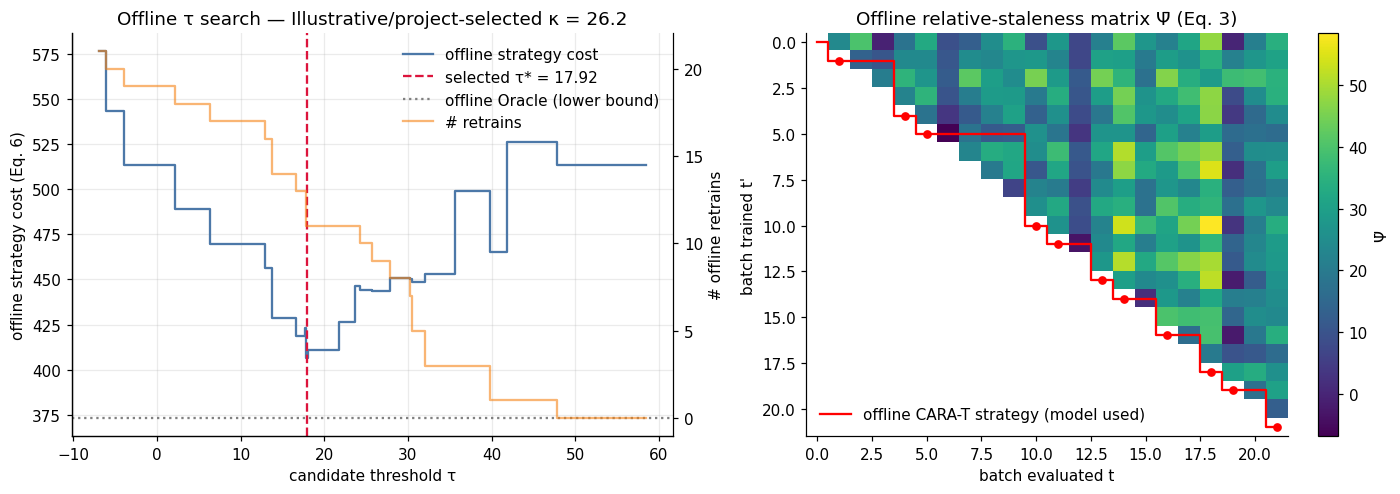

In [33]:
THRESH_TABLE, SEL = TAB_BY_K[KAPPA_DEFAULT], SEL_BY_K[KAPPA_DEFAULT]
KAPPA_PRIMARY = KAPPA_DEFAULT                     # kappa used by the detailed single-κ run
C_OFF = build_cost_matrix(PSIBAR_OFF, KAPPA_PRIMARY)

print(f"{RUN_KIND}: κ = {KAPPA_PRIMARY:.4f}  [{KAPPA_SOURCES[KAPPA_PRIMARY]}]")
print(f"candidate thresholds evaluated (exhaustive, one per plateau): {len(THRESH_TABLE)}")
print(f"SELECTED  tau* = {SEL['tau']:.4f}   plateau = ({SEL['plateau'][0]}, {SEL['plateau'][1]}]  (midpoint chosen)")
print(f"          offline CARA-T cost = {SEL['offline_cost']:.2f}  | offline retrains = {SEL['n_retrains']}")
print(f"          offline Oracle (DP, Eq. 12-14) lower bound = {SEL['oracle_cost']:.2f}")
print(f"          dual_annealing cross-check cost = {SEL['dual_annealing_cost']:.2f}  (must be >= exhaustive optimum)")
print(f"          optimal plateaus tied: {SEL['n_tied_optimal_plateaus']} (tie-break: fewer retrains, then larger tau)")
if SEL["n_retrains"] == 0:
    print("[note] offline optimum = never retrain; CARA-T degenerates to NR at this kappa.")
if SEL["n_retrains"] >= T_OFF - 1:
    print("[note] offline optimum = retrain at every batch; CARA-T degenerates to Always Retrain at this kappa.")
print("\nTen cheapest candidate thresholds:")
display(THRESH_TABLE.sort_values("offline_strategy_cost").head(10))

tab_out = THRESH_TABLE.copy(); tab_out.insert(0, "kappa", KAPPA_PRIMARY); tab_out.insert(1, "run_kind", RUN_KIND)
tab_out.to_csv(RESULTS_DIR / "cara_t_threshold_selection.csv", index=False)

def _py(o):
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):     return o.tolist()
    if isinstance(o, (Path,)):        return str(o)
    raise TypeError(type(o))

def _fin(x):
    return None if (x is None or not np.isfinite(x)) else float(x)

SELECTED_PARAMS = dict(
    variant="CARA-T", rule="Keep if relative staleness Psi_bar < tau else Retrain (paper Eq. 8)",
    run_kind=RUN_KIND, tau_star=SEL["tau"],
    tau_plateau_low_exclusive=_fin(SEL["plateau"][0]), tau_plateau_high_inclusive=_fin(SEL["plateau"][1]),
    kappa=KAPPA_PRIMARY, kappa_source=KAPPA_SOURCES[KAPPA_PRIMARY],
    kappa_note=("user-specified external cost" if KAPPA_PRIMARY_ABS is not None else
                "Illustrative/project-selected kappa = multiple of a project-convenience reference scale (median positive offline Psi_bar = "
                f"{KAPPA_REF_SCALE:.6f}); NOT paper-defined, NOT a real-world (monetary) cost or exchange rate"),
    gamma=GAMMA, similarity_dim=SIM_DIM, query_fraction=QUERY_FRACTION, seed=SEED,
    offline_batches=[OFFLINE_IDS[0], OFFLINE_IDS[-1]], online_batches=[ONLINE_IDS[0], ONLINE_IDS[-1]],
    offline_cara_t_cost=SEL["offline_cost"], offline_cara_t_retrains=SEL["n_retrains"],
    offline_oracle_cost=SEL["oracle_cost"], offline_oracle_retrains=SEL["oracle_retrains"],
    dual_annealing_cross_check_cost=_fin(SEL["dual_annealing_cost"]), n_candidate_thresholds=int(len(THRESH_TABLE)),
    selection="exhaustive over all decision plateaus; midpoint of optimal plateau; tie-break fewer retrains then larger tau",
    uses_batches_22_24=False, uses_batches_25_99=False)
with open(RESULTS_DIR / "cara_t_selected_params.json", "w") as fh:
    json.dump(SELECTED_PARAMS, fh, indent=2, default=_py)
print("saved:", RESULTS_DIR / "cara_t_threshold_selection.csv", "and", RESULTS_DIR / "cara_t_selected_params.json")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.step(THRESH_TABLE.tau, THRESH_TABLE.offline_strategy_cost, where="mid", color="#4C78A8", label="offline strategy cost")
ax.axvline(SEL["tau"], color="crimson", ls="--", label=f"selected τ* = {SEL['tau']:.2f}")
ax.axhline(SEL["oracle_cost"], color="gray", ls=":", label="offline Oracle (lower bound)")
ax.set_xlabel("candidate threshold τ"); ax.set_ylabel("offline strategy cost (Eq. 6)")
ax.set_title(f"Offline τ search — {RUN_TAG}")
ax2 = ax.twinx(); ax2.grid(False)
ax2.step(THRESH_TABLE.tau, THRESH_TABLE.n_retrains, where="mid", color="#F58518", alpha=.6, label="# retrains")
ax2.set_ylabel("# offline retrains"); ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper right")
ax = axes[1]
im = ax.imshow(np.ma.masked_invalid(PSIBAR_OFF), aspect="auto", cmap="viridis")
S_off = SEL["strategy"]
ax.step(range(T_OFF), S_off, where="mid", color="red", lw=1.5, label="offline CARA-T strategy (model used)")
rt = [t for t in range(1, T_OFF) if S_off[t] == t]
ax.scatter(rt, rt, color="red", zorder=3, s=22)
ax.set_xlabel("batch evaluated t"); ax.set_ylabel("batch trained t'"); ax.set_title("Offline relative-staleness matrix Ψ̄ (Eq. 3)")
plt.colorbar(im, ax=ax, label="Ψ̄"); ax.legend(loc="lower left"); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG_DIR / "00_offline_threshold_selection.png", bbox_inches="tight"); plt.show()

## Cell 14 — Phase C protocol (prequential test-then-train, Algorithm 1 + Sec. 7.5)

For every online batch $t=25,\dots,99$ (in file order):

1. the **currently deployed** model predicts batch $t$ → prediction metrics (full batch and paper's *query accuracy* on $Q_t$);
2. relative staleness $\overline\Psi_{t,t'}$ (Eq. 3) is computed for that model — this uses the *labels of batch $t$*, which are legitimately available only after prediction;
3. CARA-T: $\overline\Psi_{t,t'}\ge\tau^*$ → `RETRAIN`, else `KEEP` (Eq. 8, τ\* frozen from the offline phase);
4. batch strategy cost = κ if `RETRAIN`, else $\overline\Psi_{t,t'}$ (Eq. 4/6);
5. **only now**, if `RETRAIN`: a new pipeline (V1 hyper-parameters) is fit **from scratch on $D_t$ only** → next version (V2, V3, …), used from batch $t+1$.

Hard guards in the code: the model used on batch $t$ must have been trained on a batch $<t$ (or be V1); holdout batches 22–24 raise an error if touched; fitted models are requested only at the batch they are trained on.

## Cell 15 — Online runner (shared by CARA-T and the baselines so that they are directly comparable)

In [34]:
def save_model_version(version_name, model, trained_on_batch, parent_version, decided_after_batch, strategy_name, extra):
    """Persist models/<vN>/model_pipeline.joblib + metadata.json. v1 can never be overwritten."""
    if version_name == "v1":
        raise RuntimeError("v1 is never overwritten")
    d = MODELS_DIR / version_name
    d.mkdir(parents=True, exist_ok=True)
    joblib.dump(model, d / "model_pipeline.joblib", compress=SAVE_MODEL_COMPRESS)
    clf = model.steps[-1][1]
    md_ = dict(
        model_version=version_name, parent_version=parent_version, created_by=strategy_name,
        retrain_decided_after_batch=int(decided_after_batch), first_batch_served=int(decided_after_batch) + 1,
        training_batch_ids=[int(trained_on_batch)], n_training_samples=int(len(get_y(trained_on_batch))),
        retraining_policy="trained from scratch on the single current batch D_t (paper Sec. 3 / App. E), "
                          "V1 pipeline structure and hyper-parameters",
        feature_columns=FEATURES, categorical_features=CATEGORICAL, numerical_features=NUMERICAL, target=TARGET,
        hyperparameters=clf.get_params(), training_time_seconds=float(FIT_SECONDS[int(trained_on_batch)]),
        random_state=SEED, sklearn_version=sklearn.__version__, pandas_version=pd.__version__,
        numpy_version=np.__version__, joblib_version=joblib.__version__,
        saved_at_utc=datetime.now(timezone.utc).isoformat(), **extra)
    with open(d / "metadata.json", "w") as fh:
        json.dump(md_, fh, indent=2, default=_py)

def run_online(name, decide, kappa, tau=np.nan, save_models=False, verbose=True):
    """Algorithm 1 over the online stream with prequential evaluation.
    decide(k=, t=, staleness=) -> True means RETRAIN.  Returns a per-batch DataFrame."""
    deployed_m, deployed_d, version = "V1", "REF", 1            # D_t' for V1 = batches 0-21 (adaptation A2)
    rows, cum = [], 0.0
    for k, t in enumerate(ONLINE_IDS):
        # leakage guard: the model answering batch t was trained strictly before t
        assert deployed_m == "V1" or int(deployed_m) < t, "model trained on the batch it is asked to predict"
        y = get_y(t)
        P = get_pred(deployed_m, t)                                         # (1) predict FIRST
        pred, proba = P["pred"], P["proba"]
        mets = batch_metrics(y, pred, proba)
        qi = query_idx(t)
        q_acc = float((pred[qi] == y[qi]).mean())
        psi_cur = psi(t, t, deployed_m)                                     # (2) staleness (Eq. 3)
        psi_trn = psi(t, deployed_d, deployed_m)
        stale = psi_cur - psi_trn
        retrain = bool(decide(k=k, t=t, staleness=stale)) if np.isfinite(stale) else False   # (3) decision
        ver_before, ver_after, fit_s = f"v{version}", f"v{version}", 0.0
        trained_on_before = -1 if deployed_m == "V1" else int(deployed_m)
        cost = float(kappa) if retrain else float(stale)                   # (4) Eq. 4 / 6
        cum += cost
        n1 = int(y.sum())
        if retrain:                                                         # (5) train only AFTER evaluating batch t
            mdl = get_model(t, now_t=t)
            fit_s = float(FIT_SECONDS[t])
            version += 1; ver_after = f"v{version}"
            if save_models:
                save_model_version(ver_after, mdl, t, ver_before, t, name,
                                   dict(tau=_fin(tau), kappa=float(kappa), staleness_at_decision=float(stale)))
            deployed_m, deployed_d = t, t
        rows.append(dict(
            strategy=name, batch_id=t, online_index=k, model_version_before_decision=ver_before,
            model_trained_on_batch=trained_on_before, number_of_samples=len(y),
            class_distribution=json.dumps({"0": len(y) - n1, "1": n1}), actual_delay_rate=n1 / len(y),
            predicted_delay_rate=float(pred.mean()), **mets, query_n=len(qi), query_accuracy=q_acc,
            psi_current_data=psi_cur, psi_training_data=psi_trn, staleness=stale, tau=tau, kappa=float(kappa),
            decision="RETRAIN" if retrain else "KEEP", retrained=retrain, model_version_after_decision=ver_after,
            retraining_time_seconds=fit_s, strategy_cost=cost, cumulative_strategy_cost=cum,
            # aliases using the project's required result-column names (the older names above are kept for the plots)
            threshold=tau, strategy_cost_contribution=cost, sample_count=len(y)))
        if verbose:
            tag = f"-> {ver_after} (fit {fit_s:.2f}s)" if retrain else ""
            print(f"[{name:<14}] batch {t:3d} | {ver_before:>4} | acc {mets['accuracy']:.3f} | "
                  f"stale {stale:9.3f} | tau {tau:9.3f} | {'RETRAIN' if retrain else 'KEEP   '} {tag}")
    return pd.DataFrame(rows)

def summarize_run(df, name, kappa):
    return dict(strategy=name, kappa=float(kappa), n_online_batches=len(df),
                total_strategy_cost=float(df.strategy_cost.sum()),
                strategy_cost_staleness_part=float(df.loc[~df.retrained, "strategy_cost"].sum()),
                strategy_cost_retraining_part=float(df.loc[df.retrained, "strategy_cost"].sum()),
                n_retrains=int(df.retrained.sum()), total_retraining_time_seconds=float(df.retraining_time_seconds.sum()),
                final_number_of_model_versions=int(1 + df.retrained.sum()),
                avg_online_accuracy=float(df.accuracy.mean()), avg_query_accuracy=float(df.query_accuracy.mean()),
                avg_online_precision=float(df.precision.mean()), avg_online_recall=float(df.recall.mean()),
                avg_online_f1=float(df.f1.mean()), avg_online_roc_auc=float(df.roc_auc.mean(skipna=True)),
                avg_online_staleness=float(df.staleness.mean()),
                pooled_online_accuracy=float((df.accuracy * df.number_of_samples).sum() / df.number_of_samples.sum()))
print("runner ready")

runner ready


## Cell 16 — PRIMARY RESULT: κ sweep over CARA-T and the comparison strategies (online, batches 25–99)

For **every κ in the grid**: τ\* and φ\* were chosen offline (Cell 12, batches 0–21 only); every strategy below is then run through the **same** `run_online` function (same queries, same Ψ̄ accounting, same κ), so costs are directly comparable.

| Strategy | Decision rule | Status |
|---|---|---|
| **CARA-T** | Keep iff Ψ̄ < τ\*(κ) | method under study (adapted) |
| **NR (Always Keep)** | always Keep, V1 forever | **paper baseline** (Sec. 7.4) |
| **Markov** | Keep iff Ψ̄ < κ (Eq. 17) | **paper baseline** (Sec. 7.4) |
| **Always Retrain** | retrain after every online batch | *additional project baseline* |
| **Periodic** | retrain iff k>0 and k mod φ\*(κ) = 0 | *project baseline inspired by the paper's CARA-P*; φ\* from offline linear search over [1, T_offline] |

The retrospective Oracle is added in Cell 17. ADWIN, DDM and CARA-CT are **not** implemented, so this is **not** the paper's full baseline set.

In [35]:
STRATEGY_STATUS = {
    "CARA-T": "method under study (paper Sec. 5.1, adapted)",
    "NR (Always Keep)": "paper baseline (Sec. 7.4)",
    "Markov": "paper baseline (Sec. 7.4, Eq. 17)",
    "Always Retrain": "additional project baseline",
    "Periodic": "project baseline inspired by paper's CARA-P (Sec. 5.3)",
    "Oracle": "paper's retrospective lower bound (Sec. 6) - NOT available online",
}

def make_strategies(kappa, tau, phi):
    # returns {name: (decision_fn, threshold_recorded)}; decision_fn(k=, t=, staleness=) -> True means RETRAIN
    return {
        "CARA-T":           (lambda k, t, staleness: staleness >= tau, tau),        # Eq. 8
        "NR (Always Keep)": (lambda k, t, staleness: False, np.nan),
        "Markov":           (lambda k, t, staleness: staleness >= kappa, kappa),    # Eq. 17: Keep iff Psi_bar < kappa
        "Always Retrain":   (lambda k, t, staleness: True, np.nan),
        "Periodic":         (lambda k, t, staleness: (k > 0 and k % phi == 0), np.nan),
    }

SWEEP_RUNS, SWEEP_ROWS = {}, []
t0 = time.time()
for kk in KAPPA_GRID:
    sel_k, phi_k = SEL_BY_K[kk], PHI_BY_K[kk]
    for nm, (fn, thr) in make_strategies(kk, sel_k["tau"], phi_k).items():
        df_ = run_online(nm, fn, kk, tau=thr, save_models=False, verbose=False)
        SWEEP_RUNS[(kk, nm)] = df_
        r = summarize_run(df_, nm, kk)
        r.update(status=STRATEGY_STATUS[nm], kappa_source=KAPPA_SOURCES[kk], threshold_used=thr,
                 phi_star=phi_k if nm == "Periodic" else np.nan)
        SWEEP_ROWS.append(r)
    cr = SWEEP_RUNS[(kk, "CARA-T")]
    print(f"  κ={kk:10.3f} [{KAPPA_SOURCES[kk][:28]:<28}] τ*={sel_k['tau']:9.3f} φ*={phi_k:2d} | "
          f"CARA-T cost {cr.strategy_cost.sum():10.2f}, retrains {int(cr.retrained.sum()):2d} | elapsed {time.time()-t0:.0f}s")

  κ=     6.549 [0.25 x project-selected refe] τ*=    5.804 φ*= 1 | CARA-T cost     469.50, retrains 67 | elapsed 163s
  κ=    13.097 [0.5 x project-selected refer] τ*=   16.373 φ*= 1 | CARA-T cost     882.09, retrains 44 | elapsed 170s
  κ=    26.194 [1 x project-selected referen] τ*=   17.924 φ*= 8 | CARA-T cost    1438.85, retrains 40 | elapsed 184s
  κ=    52.388 [2 x project-selected referen] τ*=   41.661 φ*=17 | CARA-T cost    2040.93, retrains  3 | elapsed 201s
  κ=   104.777 [4 x project-selected referen] τ*=   58.461 φ*=22 | CARA-T cost    2387.75, retrains  1 | elapsed 214s
  κ=   209.553 [8 x project-selected referen] τ*=   58.461 φ*=22 | CARA-T cost    2492.53, retrains  1 | elapsed 219s
  κ=   419.106 [16 x project-selected refere] τ*=   58.461 φ*=22 | CARA-T cost    2702.08, retrains  1 | elapsed 223s
  κ=   838.212 [32 x project-selected refere] τ*=   58.461 φ*=22 | CARA-T cost    3121.19, retrains  1 | elapsed 227s
  κ=  1676.424 [64 x project-selected refere] τ*=   58.4

## Cell 17 — Retrospective Oracle (paper Sec. 6) — a lower bound, **not** an online method

The Oracle sees **every online batch's labels and queries in advance**: it builds the *complete* online cost matrix (all models $M_p$, $p\in[25,99]$, plus V1, against all later batches) and solves the dynamic programme of Eq. 12–14 (V1 uncharged at the start, adaptation A9). A real online system can never do this, so Oracle numbers are only a reference floor against which CARA-T's *online* decisions are measured (SCPE). It is computed **after** all online strategies above have run, is **not** used by any decision, and does not alter the CARA-T experiment. Its decisions are replayed through the same `run_online` and the DP cost is asserted to equal the replayed strategy cost.

In [36]:
def compute_online_staleness_matrices():
    # Retrospective: relative staleness of V1 and of every single-batch model p against every later online batch.
    n = len(ONLINE_IDS)
    v1_row = np.array([relative_staleness(t, "V1", "REF") for t in ONLINE_IDS])
    P = np.full((n, n), np.nan)                              # P[i, j] = Psi_bar_{t_j, t_i} for j > i
    t0_ = time.time()
    for i, p in enumerate(ONLINE_IDS):
        get_model(p)                                         # fit on D_p only (cached)
        for j in range(i + 1, n):
            P[i, j] = relative_staleness(ONLINE_IDS[j], p, p)
        if i % 10 == 0 or i == n - 1:
            print(f"  oracle matrix: model {i+1}/{n} | elapsed {time.time()-t0_:.0f}s")
    return v1_row, P

def oracle_online(v1_row, P, kappa):
    # DP of Eq. 13-14 with V1 as the free initial model. opt[j] = optimal cost of online batches 0..j-1.
    n = len(v1_row)
    opt = np.zeros(n + 1); arg = [-1] * n
    for j in range(n):
        best, choice = float(v1_row[:j + 1].sum()), -1       # V1 answers every batch up to j
        for i in range(j + 1):                               # last retrain at online index i (charged kappa at i)
            c = opt[i] + kappa + float(P[i, i + 1:j + 1].sum())
            if c < best:
                best, choice = c, i
        opt[j + 1], arg[j] = best, choice
    rs, j = [], n - 1
    while j >= 0:
        c = arg[j]
        if c == -1:
            break
        rs.append(ONLINE_IDS[c]); j = c - 1
    return float(opt[n]), sorted(rs)

ORACLE_INFO = {}
if RUN_ONLINE_ORACLE:
    print("Computing the retrospective online cost matrix (uses ALL online labels; reference only) ...")
    V1_ROW, P_ON = compute_online_staleness_matrices()
    for kk in KAPPA_GRID:
        cost_opt, rset = oracle_online(V1_ROW, P_ON, kk)
        S_ = set(rset)
        df_ = run_online("Oracle", (lambda k, t, staleness, S=S_: t in S), kk, tau=np.nan, save_models=False, verbose=False)
        assert np.isclose(df_.strategy_cost.sum(), cost_opt, rtol=1e-6, atol=1e-6), "Oracle DP cost != replayed strategy cost"
        SWEEP_RUNS[(kk, "Oracle")] = df_
        r = summarize_run(df_, "Oracle", kk)
        r.update(status=STRATEGY_STATUS["Oracle"], kappa_source=KAPPA_SOURCES[kk], threshold_used=np.nan, phi_star=np.nan)
        SWEEP_ROWS.append(r)
        ORACLE_INFO[kk] = dict(cost=cost_opt, retrain_batches=rset)
        print(f"  κ={kk:10.3f} | Oracle cost {cost_opt:10.2f} | retrains {len(rset):2d}")
else:
    print("RUN_ONLINE_ORACLE = False -> Oracle skipped (SCPE will be NaN)")

Computing the retrospective online cost matrix (uses ALL online labels; reference only) ...
  oracle matrix: model 1/75 | elapsed 9s
  oracle matrix: model 11/75 | elapsed 87s
  oracle matrix: model 21/75 | elapsed 148s
  oracle matrix: model 31/75 | elapsed 202s
  oracle matrix: model 41/75 | elapsed 238s
  oracle matrix: model 51/75 | elapsed 262s
  oracle matrix: model 61/75 | elapsed 279s
  oracle matrix: model 71/75 | elapsed 285s
  oracle matrix: model 75/75 | elapsed 285s
  κ=     6.549 | Oracle cost     468.76 | retrains 64
  κ=    13.097 | Oracle cost     843.04 | retrains 50
  κ=    26.194 | Oracle cost    1367.58 | retrains 28
  κ=    52.388 | Oracle cost    1825.31 | retrains 11
  κ=   104.777 | Oracle cost    1974.44 | retrains  2
  κ=   209.553 | Oracle cost    2107.78 | retrains  1
  κ=   419.106 | Oracle cost    2317.33 | retrains  1
  κ=   838.212 | Oracle cost    2376.29 | retrains  0
  κ=  1676.424 | Oracle cost    2376.29 | retrains  0


## Cell 18 — Sweep results (PRIMARY): tables, SCPE vs Oracle, plots, save

saved -> /kaggle/working/results/kappa_sweep_all_strategies.csv   (one row per κ x strategy)
saved -> /kaggle/working/results/kappa_sensitivity.csv   (PRIMARY RESULT; one row per κ)


,kappa,kappa_source,used_in_detailed_run,optimal_tau,offline_strategy_cost,number_of_retrains,offline_oracle_cost,online_cara_t_strategy_cost,online_cara_t_retrains,periodic_phi_star
0,6.5485,0.25 x project-selected reference scale,False,5.8043,115.9950,18,115.9950,469.5032,67,1
1,13.0971,0.5 x project-selected reference scale,False,16.3732,232.0237,14,232.0237,882.0914,44,1
2,26.1941,1 x project-selected reference scale,True,17.9245,406.3019,11,373.3304,"1,438.8515",40,8
3,52.3883,2 x project-selected reference scale,False,41.6611,517.5387,1,467.9200,"2,040.9310",3,17
4,104.7765,4 x project-selected reference scale,False,58.4612,592.0916,0,572.6965,"2,387.7543",1,22
5,209.5530,8 x project-selected reference scale,False,58.4612,696.8681,0,696.8681,"2,492.5308",1,22
6,419.1060,16 x project-selected reference scale,False,58.4612,906.4211,0,906.4211,"2,702.0838",1,22
7,838.2120,32 x project-selected reference scale,False,58.4612,"1,325.5271",0,"1,325.5271","3,121.1898",1,22
8,"1,676.4240",64 x project-selected reference scale,False,58.4612,"2,163.7392",0,"2,163.7392","3,959.4018",1,22



Total strategy cost (lower is better)


strategy,CARA-T,NR (Always Keep),Markov,Always Retrain,Periodic,Oracle
kappa,,,,,,
6.5485,469.5032,"2,376.2904",468.9467,491.1398,490.0415,468.7638
13.0971,882.0914,"2,376.2904",843.0443,982.2797,974.6329,843.0443
26.1941,"1,438.8515","2,376.2904","1,544.7363","1,964.5594","2,145.7537","1,367.5830"
52.3883,"2,040.9310","2,376.2904","2,217.2544","3,929.1188","2,099.4505","1,825.3149"
104.7765,"2,387.7543","2,376.2904","2,376.2904","7,858.2376","2,479.1293","1,974.4441"
209.5530,"2,492.5308","2,376.2904","2,376.2904","15,716.4751","2,793.4588","2,107.7809"
419.1060,"2,702.0838","2,376.2904","2,376.2904","31,432.9502","3,422.1178","2,317.3339"
838.2120,"3,121.1898","2,376.2904","2,376.2904","62,865.9003","4,679.4358","2,376.2904"
"1,676.4240","3,959.4018","2,376.2904","2,376.2904","125,731.8008","7,194.0718","2,376.2904"



SCPE vs retrospective Oracle, % (lower is better)


...

strategy,CARA-T,NR (Always Keep),Markov,Always Retrain,Periodic,Oracle
kappa,,,,,,
6.5485,67,0,66,75,74,64
13.0971,44,0,50,75,74,50
26.1941,40,0,32,75,9,28
52.3883,3,0,1,75,4,11
104.7765,1,0,0,75,3,2
209.5530,1,0,0,75,3,1
419.1060,1,0,0,75,3,1
838.2120,1,0,0,75,3,0
"1,676.4240",1,0,0,75,3,0



Average online query accuracy


strategy,CARA-T,NR (Always Keep),Markov,Always Retrain,Periodic,Oracle
kappa,,,,,,
6.5485,0.6369,0.6030,0.6366,0.6375,0.6377,0.6371
13.0971,0.6425,0.6030,0.6407,0.6375,0.6377,0.6407
26.1941,0.6410,0.6030,0.6333,0.6375,0.6145,0.6448
52.3883,0.6104,0.6030,0.6078,0.6375,0.6197,0.6346
104.7765,0.5942,0.6030,0.6030,0.6375,0.6034,0.6177
209.5530,0.5942,0.6030,0.6030,0.6375,0.6034,0.6184
419.1060,0.5942,0.6030,0.6030,0.6375,0.6034,0.6184
838.2120,0.5942,0.6030,0.6030,0.6375,0.6034,0.6030
"1,676.4240",0.5942,0.6030,0.6030,0.6375,0.6034,0.6030



Average online staleness Ψ̄


strategy,CARA-T,NR (Always Keep),Markov,Always Retrain,Periodic,Oracle
kappa,,,,,,
6.5485,21.1162,31.6839,21.0803,21.2310,21.0738,20.8567
13.0971,19.5351,31.6839,19.4228,21.2310,21.0738,19.4228
26.1941,20.0214,31.6839,24.1160,21.2310,29.3766,18.7662
52.3883,26.8667,31.6839,29.5919,21.2310,26.8076,21.5954
104.7765,31.2464,31.6839,31.6839,21.2310,29.9017,24.2808
209.5530,31.2464,31.6839,31.6839,21.2310,29.9017,25.8481
419.1060,31.2464,31.6839,31.6839,21.2310,29.9017,25.8481
838.2120,31.2464,31.6839,31.6839,21.2310,29.9017,31.6839
"1,676.4240",31.2464,31.6839,31.6839,21.2310,29.9017,31.6839


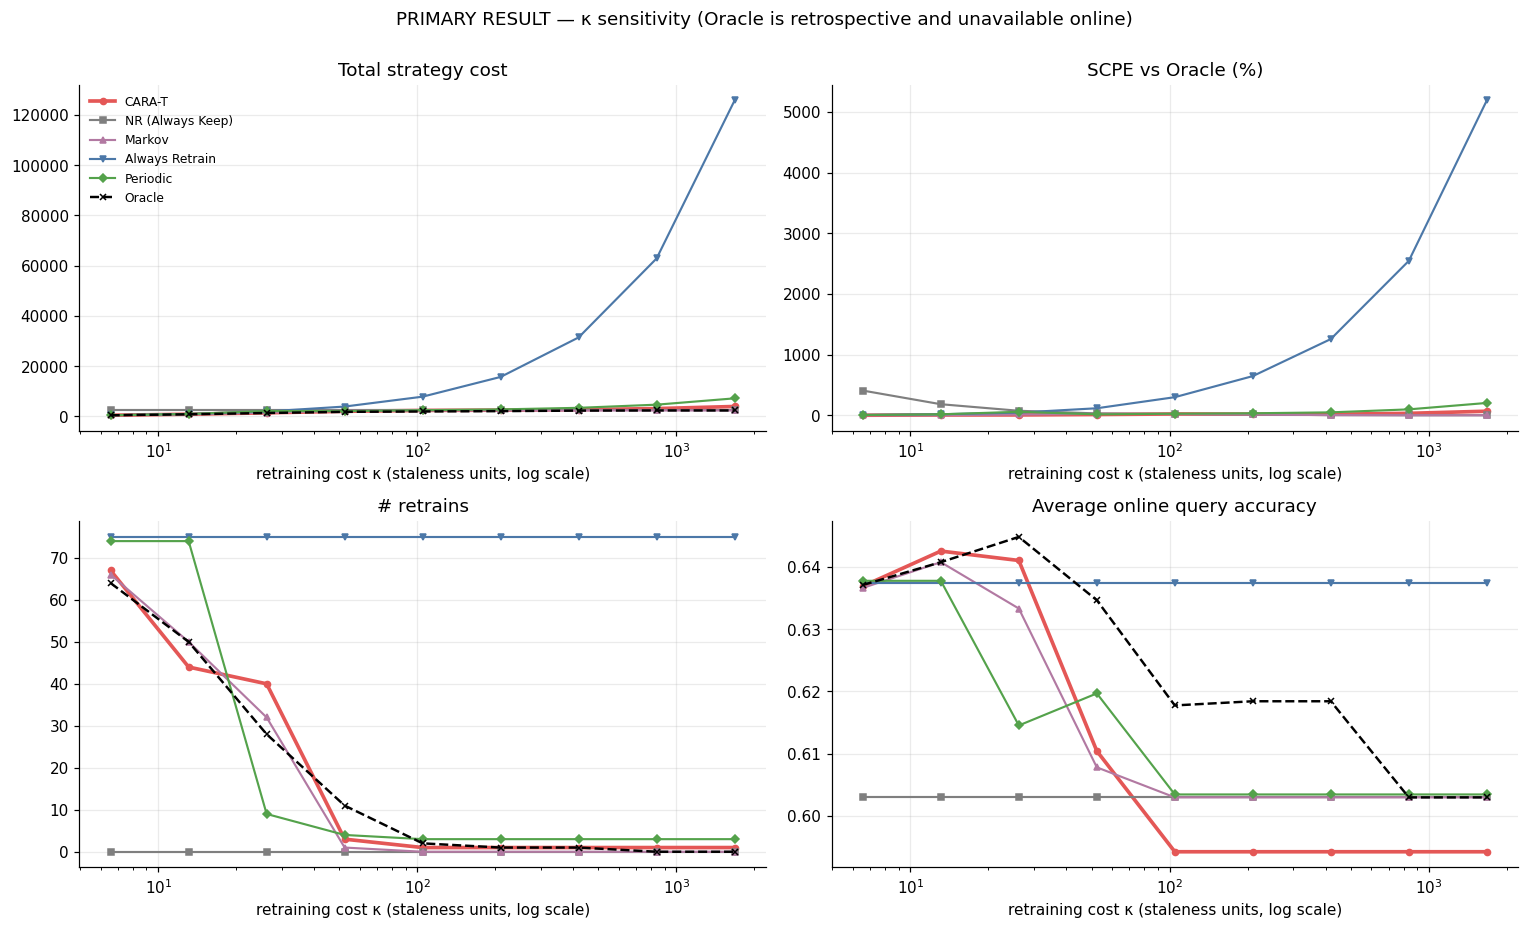

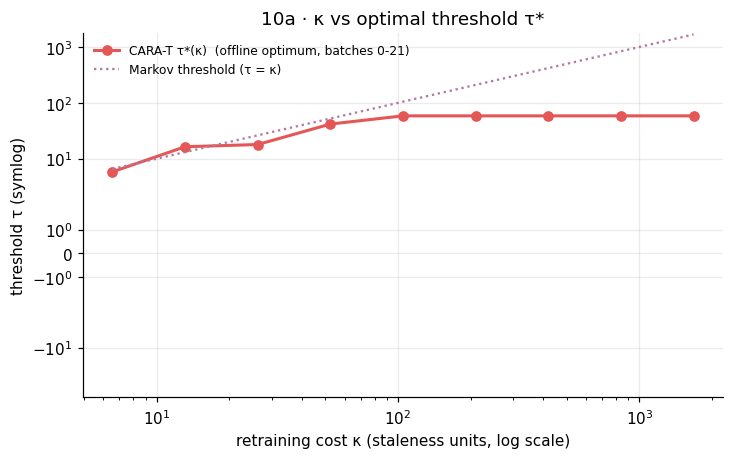

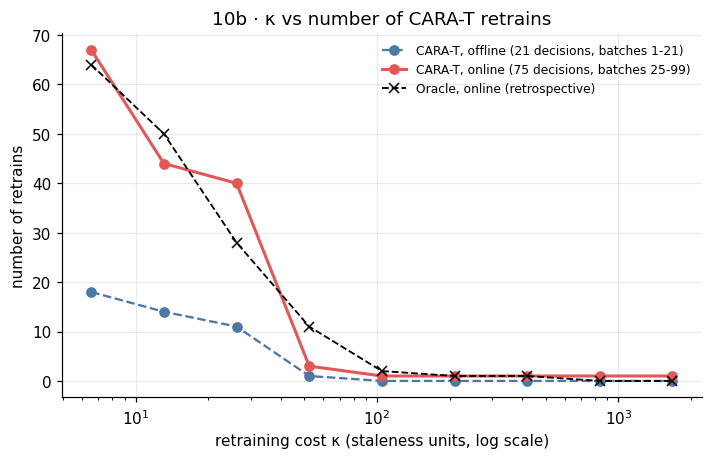

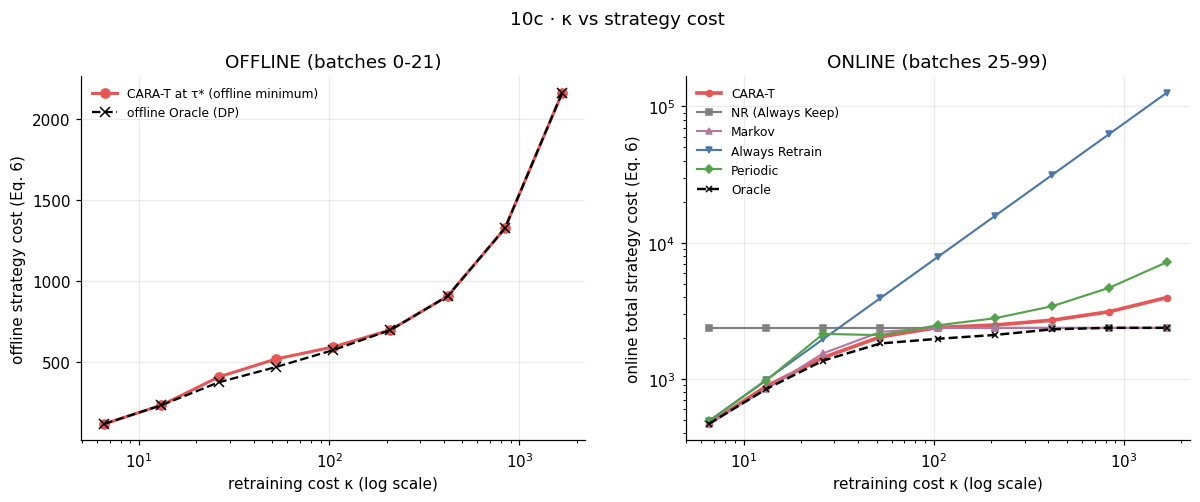

In [37]:
SWEEP = pd.DataFrame(SWEEP_ROWS)
orc = SWEEP[SWEEP.strategy == "Oracle"].set_index("kappa")["total_strategy_cost"]
def _scpe(row):                                   # paper Sec. 7.5: PE = 100*|b-a|/|b|, b = Oracle cost, a = strategy cost
    b = orc.get(row["kappa"], np.nan)
    return np.nan if (not np.isfinite(b) or abs(b) < 1e-12) else 100.0 * abs(b - row["total_strategy_cost"]) / abs(b)
SWEEP["scpe_vs_oracle_pct"] = SWEEP.apply(_scpe, axis=1)
SWEEP.loc[SWEEP.strategy == "Oracle", "scpe_vs_oracle_pct"] = np.nan
SWEEP.to_csv(RESULTS_DIR / "kappa_sweep_all_strategies.csv", index=False)
print("saved ->", RESULTS_DIR / "kappa_sweep_all_strategies.csv", "  (one row per κ x strategy)")

# ---- results/kappa_sensitivity.csv : ONE ROW PER κ  (PRIMARY RESULT) ----
#   optimal_tau / offline_strategy_cost / number_of_retrains / offline_retrain_batches : offline optimum of CARA-T (batches 0-21)
#   online_* : what that frozen τ* then did on the online stream (batches 25-99)
_rows_k = []
for kk in KAPPA_GRID:
    s_k, c_k = SEL_BY_K[kk], SWEEP_RUNS[(kk, "CARA-T")]
    _rows_k.append(dict(
        kappa=kk, kappa_source=KAPPA_SOURCES[kk], used_in_detailed_run=bool(kk == KAPPA_PRIMARY),
        optimal_tau=s_k["tau"], offline_strategy_cost=s_k["offline_cost"], number_of_retrains=s_k["n_retrains"],
        offline_retrain_batches=json.dumps([t for t in range(1, T_OFF) if s_k["strategy"][t] == t]),
        offline_oracle_cost=s_k["oracle_cost"],
        online_cara_t_strategy_cost=float(c_k.strategy_cost.sum()), online_cara_t_retrains=int(c_k.retrained.sum()),
        online_retrain_batches=json.dumps([int(b) for b in c_k.loc[c_k.retrained, "batch_id"]]),
        periodic_phi_star=PHI_BY_K[kk]))
KAPPA_SENS = pd.DataFrame(_rows_k)
KAPPA_SENS.to_csv(RESULTS_DIR / "kappa_sensitivity.csv", index=False)
print("saved ->", RESULTS_DIR / "kappa_sensitivity.csv", "  (PRIMARY RESULT; one row per κ)")
display(KAPPA_SENS.drop(columns=["offline_retrain_batches", "online_retrain_batches"]))

order = [s for s in ["CARA-T", "NR (Always Keep)", "Markov", "Always Retrain", "Periodic", "Oracle"] if s in set(SWEEP.strategy)]
for col, ttl in [("total_strategy_cost", "Total strategy cost (lower is better)"),
                 ("scpe_vs_oracle_pct", "SCPE vs retrospective Oracle, % (lower is better)"),
                 ("n_retrains", "Number of retrains"),
                 ("avg_query_accuracy", "Average online query accuracy"),
                 ("avg_online_staleness", "Average online staleness Ψ̄")]:
    print("\n" + ttl)
    display(SWEEP.pivot(index="kappa", columns="strategy", values=col)[order])

sty = {"CARA-T": dict(color="#E45756", lw=2.4, marker="o"), "NR (Always Keep)": dict(color="#7F7F7F", lw=1.4, marker="s"),
       "Markov": dict(color="#B279A2", lw=1.4, marker="^"), "Always Retrain": dict(color="#4C78A8", lw=1.4, marker="v"),
       "Periodic": dict(color="#54A24B", lw=1.4, marker="D"), "Oracle": dict(color="black", lw=1.6, ls="--", marker="x")}
fig, axes = plt.subplots(2, 2, figsize=(14, 8.4))
for ax, col, ttl in zip(axes.ravel(), ["total_strategy_cost", "scpe_vs_oracle_pct", "n_retrains", "avg_query_accuracy"],
                        ["Total strategy cost", "SCPE vs Oracle (%)", "# retrains", "Average online query accuracy"]):
    for nm in order:
        g = SWEEP[SWEEP.strategy == nm].sort_values("kappa")
        if col == "scpe_vs_oracle_pct" and nm == "Oracle":
            continue
        ax.plot(g.kappa, g[col], ms=4, label=nm, **sty[nm])
    ax.set_xscale("log"); ax.set_xlabel("retraining cost κ (staleness units, log scale)"); ax.set_title(ttl)
axes[0, 0].legend(fontsize=8)
fig.suptitle("PRIMARY RESULT — κ sensitivity (Oracle is retrospective and unavailable online)", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "09_kappa_sensitivity.png", bbox_inches="tight"); plt.show()

# ---- dedicated κ-sensitivity figures: 10a κ vs τ*, 10b κ vs # retrains, 10c κ vs strategy cost ----
ks = KAPPA_SENS.sort_values("kappa")
_lin = max(1e-3, 0.1 * KAPPA_REF_SCALE)

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(ks.kappa, ks.optimal_tau, "o-", color="#E45756", lw=2, label="CARA-T τ*(κ)  (offline optimum, batches 0-21)")
ax.plot(ks.kappa, ks.kappa, ":", color="#B279A2", label="Markov threshold (τ = κ)")
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=_lin)
ax.set_xlabel("retraining cost κ (staleness units, log scale)"); ax.set_ylabel("threshold τ (symlog)")
ax.set_title("10a · κ vs optimal threshold τ*"); ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "10a_kappa_vs_tau_star.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(ks.kappa, ks.number_of_retrains, "o--", color="#4C78A8", label="CARA-T, offline (21 decisions, batches 1-21)")
ax.plot(ks.kappa, ks.online_cara_t_retrains, "o-", color="#E45756", lw=2, label="CARA-T, online (75 decisions, batches 25-99)")
_o = SWEEP[SWEEP.strategy == "Oracle"].sort_values("kappa")
if len(_o):
    ax.plot(_o.kappa, _o.n_retrains, "x--", color="black", lw=1.2, label="Oracle, online (retrospective)")
ax.set_xscale("log"); ax.set_xlabel("retraining cost κ (staleness units, log scale)"); ax.set_ylabel("number of retrains")
ax.set_title("10b · κ vs number of CARA-T retrains"); ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "10b_kappa_vs_retrains.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(ks.kappa, ks.offline_strategy_cost, "o-", color="#E45756", lw=2, label="CARA-T at τ* (offline minimum)")
ax.plot(ks.kappa, ks.offline_oracle_cost, "x--", color="black", label="offline Oracle (DP)")
ax.set_xscale("log"); ax.set_xlabel("retraining cost κ (log scale)"); ax.set_ylabel("offline strategy cost (Eq. 6)")
ax.set_title("OFFLINE (batches 0-21)"); ax.legend(fontsize=8)
ax = axes[1]
for nm in order:
    g = SWEEP[SWEEP.strategy == nm].sort_values("kappa")
    ax.plot(g.kappa, g.total_strategy_cost, ms=4, label=nm, **sty[nm])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("retraining cost κ (log scale)"); ax.set_ylabel("online total strategy cost (Eq. 6)")
ax.set_title("ONLINE (batches 25-99)"); ax.legend(fontsize=8)
fig.suptitle("10c · κ vs strategy cost", y=1.02)
fig.savefig(FIG_DIR / "10c_kappa_vs_strategy_cost.png", bbox_inches="tight"); plt.show()


## Cell 19 — Detailed CARA-T run at ONE κ (per-batch results, model versions V2, V3, …)

This is the run that saves model versions and per-batch records. **Unless you set `KAPPA_PRIMARY_ABS`, its κ is the *Illustrative/project-selected κ*** (Cell 11; not paper-defined, not a real-world cost) and the run must be read as an *illustration of how CARA-T behaves*, not as the result for any real cost. The headline evidence is the κ sweep (Cells 16–18). The run re-executes exactly the CARA-T strategy of the sweep at this κ (asserted identical) with model saving switched on. `models/v1` is never touched; older `v2…vN` folders from a previous run of this notebook are deleted first so no stale versions remain.

In [38]:
TAU_STAR = SELECTED_PARAMS["tau_star"]
print(f"{RUN_KIND} | CARA-T tau* = {TAU_STAR:.4f} | kappa = {KAPPA_PRIMARY:.4f} | batches {ONLINE_IDS[0]}..{ONLINE_IDS[-1]}\n")

for _p in MODELS_DIR.iterdir():                                   # remove stale versions from earlier runs; v1 is NEVER removed
    if _p.is_dir() and re.match(r"^v([2-9]|\d{2,})$", _p.name):
        shutil.rmtree(_p)
assert (MODELS_DIR / "v1" / "model_pipeline.joblib").exists()

t0 = time.time()
cara_t_decide = lambda k, t, staleness: staleness >= TAU_STAR      # Eq. 8
CARA_T_DF = run_online("CARA-T", cara_t_decide, KAPPA_PRIMARY, tau=TAU_STAR, save_models=True, verbose=True)
print(f"\nonline run finished in {time.time()-t0:.0f}s")

# identical to the CARA-T run inside the sweep (determinism check)
_ref = SWEEP_RUNS[(KAPPA_PRIMARY, "CARA-T")]
assert (_ref.decision.values == CARA_T_DF.decision.values).all() and np.allclose(_ref.strategy_cost.values, CARA_T_DF.strategy_cost.values)

# ---- integrity checks of the prequential ordering ----
_dep = CARA_T_DF.model_trained_on_batch.values
assert all(_dep[i] < CARA_T_DF.batch_id.values[i] for i in range(len(CARA_T_DF))), "prequential order violated"
for i in range(len(CARA_T_DF[CARA_T_DF.retrained])):
    b = int(CARA_T_DF[CARA_T_DF.retrained].iloc[i].batch_id)
    nxt = CARA_T_DF[CARA_T_DF.batch_id == b + 1]
    if len(nxt):
        assert int(nxt.iloc[0].model_trained_on_batch) == b, "new model must first be used on the NEXT batch"
assert ((CARA_T_DF.staleness >= TAU_STAR) == CARA_T_DF.retrained).all(), "decisions do not follow Eq. 8"
print("prequential integrity checks passed (decision at t uses data up to t; new model first serves t+1; single-batch retraining).")
display(CARA_T_DF[["batch_id", "model_version_before_decision", "accuracy", "query_accuracy", "staleness", "decision",
                   "model_version_after_decision", "retraining_time_seconds", "strategy_cost"]].head(12))

Illustrative/project-selected κ | CARA-T tau* = 17.9245 | kappa = 26.1941 | batches 25..99

[CARA-T        ] batch  25 |   v1 | acc 0.716 | stale     5.450 | tau    17.924 | KEEP    
[CARA-T        ] batch  26 |   v1 | acc 0.730 | stale    15.833 | tau    17.924 | KEEP    
[CARA-T        ] batch  27 |   v1 | acc 0.662 | stale    24.978 | tau    17.924 | RETRAIN -> v2 (fit 0.40s)
[CARA-T        ] batch  28 |   v2 | acc 0.661 | stale     9.148 | tau    17.924 | KEEP    
[CARA-T        ] batch  29 |   v2 | acc 0.676 | stale    26.190 | tau    17.924 | RETRAIN -> v3 (fit 0.40s)
[CARA-T        ] batch  30 |   v3 | acc 0.625 | stale    26.044 | tau    17.924 | RETRAIN -> v4 (fit 0.37s)
[CARA-T        ] batch  31 |   v4 | acc 0.701 | stale     9.451 | tau    17.924 | KEEP    
[CARA-T        ] batch  32 |   v4 | acc 0.710 | stale     3.463 | tau    17.924 | KEEP    
[CARA-T        ] batch  33 |   v4 | acc 0.676 | stale    18.886 | tau    17.924 | RETRAIN -> v5 (fit 0.40s)
[CARA-T        ] batc

,batch_id,model_version_before_decision,accuracy,query_accuracy,staleness,decision,model_version_after_decision,retraining_time_seconds,strategy_cost
0,25,v1,0.7162,0.7217,5.4502,KEEP,v1,0.0000,5.4502
1,26,v1,0.7295,0.7013,15.8332,KEEP,v1,0.0000,15.8332
2,27,v1,0.6622,0.6920,24.9778,RETRAIN,v2,0.3957,26.1941
3,28,v2,0.6611,0.6865,9.1481,KEEP,v2,0.0000,9.1481
4,29,v2,0.6761,0.6642,26.1899,RETRAIN,v3,0.4035,26.1941
5,30,v3,0.6248,0.6141,26.0440,RETRAIN,v4,0.3730,26.1941
6,31,v4,0.7008,0.6883,9.4509,KEEP,v4,0.0000,9.4509
7,32,v4,0.7099,0.7161,3.4632,KEEP,v4,0.0000,3.4632
8,33,v4,0.6761,0.6827,18.8864,RETRAIN,v5,0.4044,26.1941
9,34,v5,0.7050,0.6827,8.0235,KEEP,v5,0.0000,8.0235


## Cell 20 — Save per-batch results and summary

In [39]:
CARA_T_SUMMARY_CORE = summarize_run(CARA_T_DF, "CARA-T", KAPPA_PRIMARY)
saved_versions = sorted([p.name for p in MODELS_DIR.iterdir() if p.is_dir() and re.match(r"^v\d+$", p.name)],
                        key=lambda s: int(s[1:]))
_digest = SWEEP[SWEEP.strategy == "CARA-T"][["kappa", "kappa_source", "threshold_used", "total_strategy_cost", "n_retrains",
                                             "avg_query_accuracy", "avg_online_accuracy", "scpe_vs_oracle_pct"]]
SUMMARY = dict(
    experiment="CARA-T on Airlines flight-delay stream (prequential, single seed)",
    adaptation_statement="This is an adaptation and operationalisation of CARA within an MLOps workflow, not a line-by-line reproduction of the paper.",
    paper="Mahadevan & Mathioudakis, Knowledge-Based Systems 293 (2024) 111610",
    generated_at_utc=datetime.now(timezone.utc).isoformat(),
    primary_result=("kappa sensitivity sweep -> results/kappa_sensitivity.csv (kappa, optimal_tau, offline_strategy_cost, number_of_retrains + online CARA-T outcome); "
                    "all strategies per kappa -> results/kappa_sweep_all_strategies.csv (CARA-T, NR, Markov, Always Retrain, Periodic, retrospective Oracle)"),
    phases=dict(v1_train_and_cara_offline=[V1_TRAIN_IDS[0], V1_TRAIN_IDS[-1]], v1_holdout=HOLDOUT_IDS,
                online=[ONLINE_IDS[0], ONLINE_IDS[-1]]),
    detailed_run=dict(
        run_kind=RUN_KIND, kappa=KAPPA_PRIMARY, kappa_source=KAPPA_SOURCES[KAPPA_PRIMARY],
        interpretation=("user-specified external retraining cost" if KAPPA_PRIMARY_ABS is not None else
                        "Illustrative/project-selected kappa only; kappa = multiple of a project-convenience reference scale "
                        "(median positive offline Psi_bar); not paper-defined, not a real-world (monetary) cost"),
        selected_parameters=SELECTED_PARAMS, online_results=CARA_T_SUMMARY_CORE,
        total_number_of_retrains=CARA_T_SUMMARY_CORE["n_retrains"],
        total_retraining_time_seconds=CARA_T_SUMMARY_CORE["total_retraining_time_seconds"],
        final_number_of_model_versions=CARA_T_SUMMARY_CORE["final_number_of_model_versions"],
        required_summary=dict(
            total_retrains=CARA_T_SUMMARY_CORE["n_retrains"],
            total_retraining_time_seconds=CARA_T_SUMMARY_CORE["total_retraining_time_seconds"],
            number_of_model_versions=CARA_T_SUMMARY_CORE["final_number_of_model_versions"],
            average_online_accuracy=CARA_T_SUMMARY_CORE["avg_online_accuracy"],
            average_online_precision=CARA_T_SUMMARY_CORE["avg_online_precision"],
            average_online_recall=CARA_T_SUMMARY_CORE["avg_online_recall"],
            average_online_f1=CARA_T_SUMMARY_CORE["avg_online_f1"],
            total_online_strategy_cost=CARA_T_SUMMARY_CORE["total_strategy_cost"]),
        saved_model_versions=saved_versions),
    kappa_sweep_cara_t=_digest.to_dict("records"),
    strategies=STRATEGY_STATUS,
    not_implemented=["ADWIN", "DDM", "CARA-CT"],
    v1_reference_holdout_metrics_from_metadata=META["metrics"],
    adaptations=["A1 offline window = batches 0-21 (22-24 reserved as untouched V1 holdout)",
                 "A2 supplied V1 trained on batches 0-21; CARA-retrained models use only the current batch; D_t' of V1 = batches 0-21",
                 "A3 kappa is not in the artifacts: sweep is primary; the single-kappa run uses an illustrative/project-selected kappa (reference-scale convenience), not paper-defined, not a real-world cost",
                 "A4 similarity: one-hot + z-scored numerics, gamma = 1/(d*Var(X_ref)) (project choice)",
                 "A5 exact exhaustive search over tau plateaus (dual_annealing cross-check); midpoint; tie-break",
                 "A6 queries = seeded random 10% of each batch",
                 "A7 periodic baseline paper-inspired: retrain iff k>0 and k mod phi == 0, phi* by offline linear search over the full range [1, T_offline]",
                 "A8 retrain batch charged kappa, keep batch charged relative staleness (Eq. 4-6)",
                 "A9 Oracle retrospective (uses all online labels), starts from V1, unavailable to a real online system"],
    library_versions=dict(python=platform.python_version(), sklearn=sklearn.__version__, pandas=pd.__version__,
                          numpy=np.__version__, scipy=scipy.__version__, joblib=joblib.__version__),
    seed=SEED)
REQUIRED_BATCH_COLS = ["batch_id", "model_version_before_decision", "accuracy", "precision", "recall", "f1", "roc_auc",
                       "staleness", "threshold", "decision", "retrained", "retraining_time_seconds",
                       "strategy_cost_contribution", "sample_count"]
_missing_cols = [c for c in REQUIRED_BATCH_COLS if c not in CARA_T_DF.columns]
assert not _missing_cols, f"required per-batch columns missing: {_missing_cols}"
_cols_out = REQUIRED_BATCH_COLS + [c for c in CARA_T_DF.columns if c not in REQUIRED_BATCH_COLS]
CARA_T_DF.assign(run_kind=RUN_KIND)[_cols_out + ["run_kind"]].to_csv(RESULTS_DIR / "cara_t_batch_results.csv", index=False)
with open(RESULTS_DIR / "cara_t_summary.json", "w") as fh:
    json.dump(SUMMARY, fh, indent=2, default=_py)
print("saved ->", RESULTS_DIR / "cara_t_batch_results.csv")
print("saved ->", RESULTS_DIR / "cara_t_summary.json")
print(f"\n=== CARA-T detailed run summary  [{RUN_KIND}, κ={KAPPA_PRIMARY:.3f}] ===")
for k_, v_ in CARA_T_SUMMARY_CORE.items():
    print(f"  {k_:34s}: {v_:,.4f}" if isinstance(v_, float) else f"  {k_:34s}: {v_}")
print("  saved model versions:", saved_versions)

saved -> /kaggle/working/results/cara_t_batch_results.csv
saved -> /kaggle/working/results/cara_t_summary.json

=== CARA-T detailed run summary  [Illustrative/project-selected κ, κ=26.194] ===
  strategy                          : CARA-T
  kappa                             : 26.1941
  n_online_batches                  : 75
  total_strategy_cost               : 1,438.8515
  strategy_cost_staleness_part      : 391.0865
  strategy_cost_retraining_part     : 1,047.7650
  n_retrains                        : 40
  total_retraining_time_seconds     : 16.2148
  final_number_of_model_versions    : 41
  avg_online_accuracy               : 0.6422
  avg_query_accuracy                : 0.6410
  avg_online_precision              : 0.6529
  avg_online_recall                 : 0.5569
  avg_online_f1                     : 0.5750
  avg_online_roc_auc                : 0.6956
  avg_online_staleness              : 20.0214
  pooled_online_accuracy            : 0.6422
  saved model versions: ['v1', 'v2', 'v3'

## Cell 21 — Plots for the detailed single-κ run (titles carry the run label)

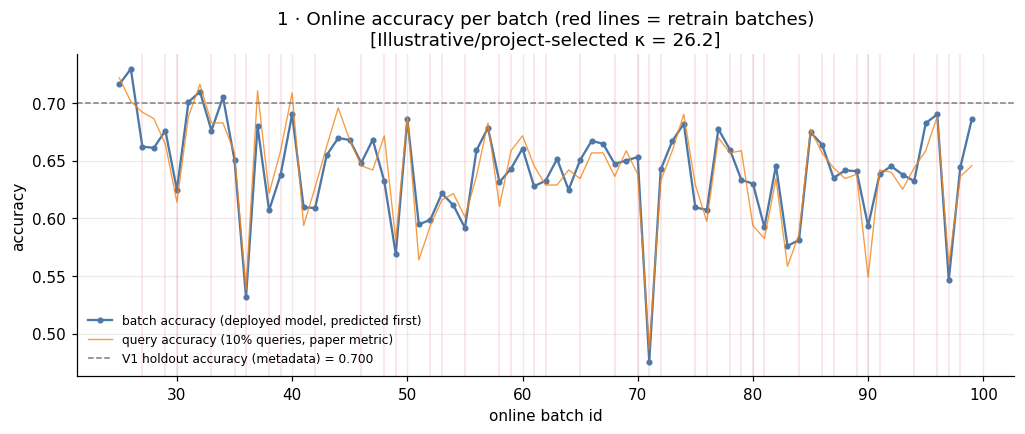

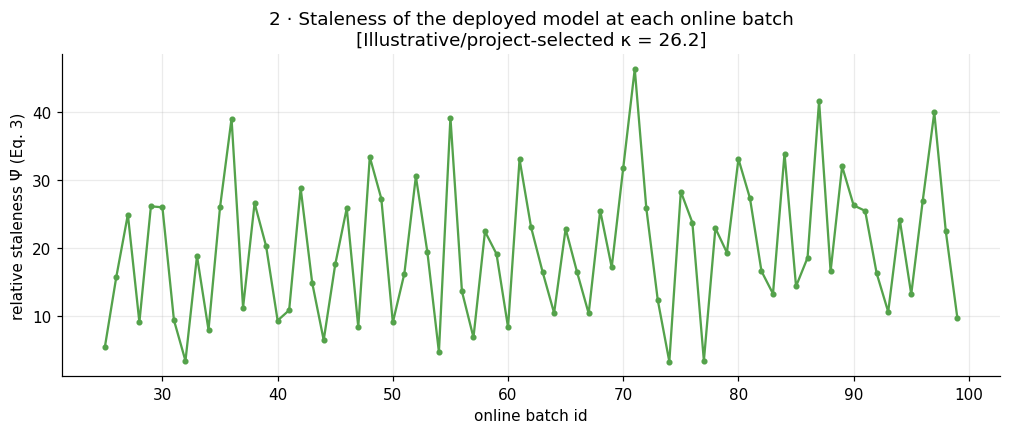

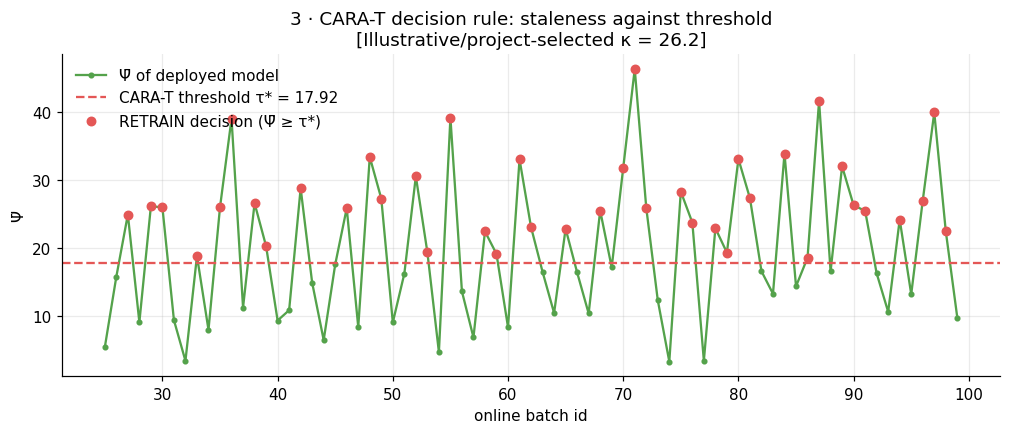

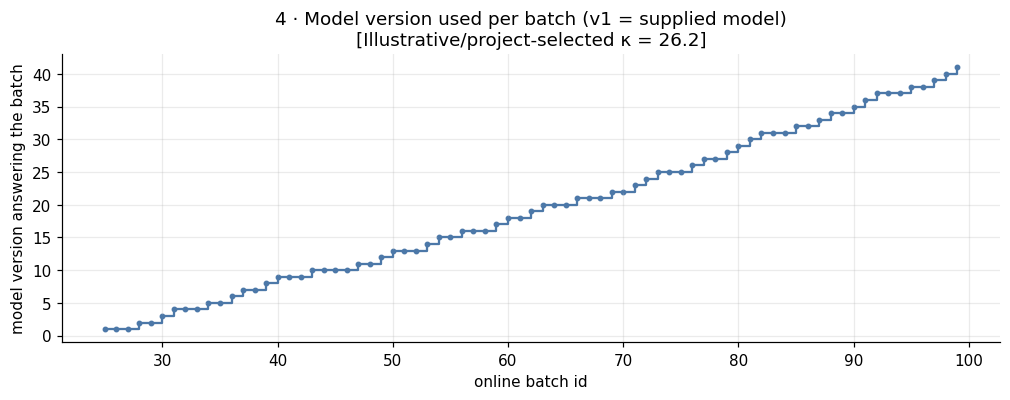

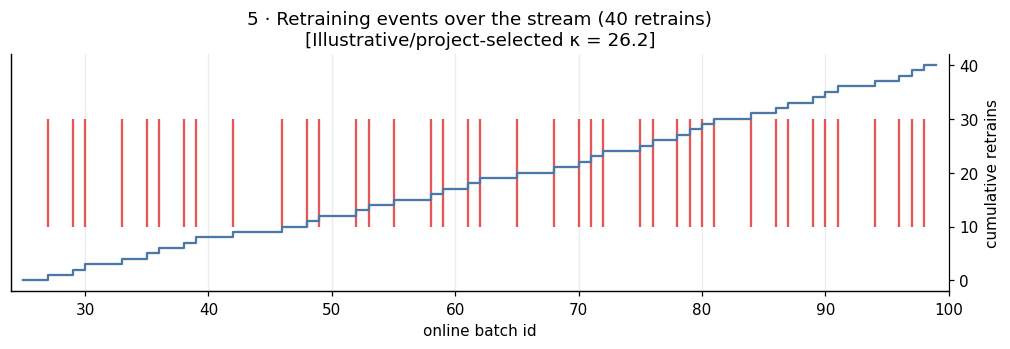

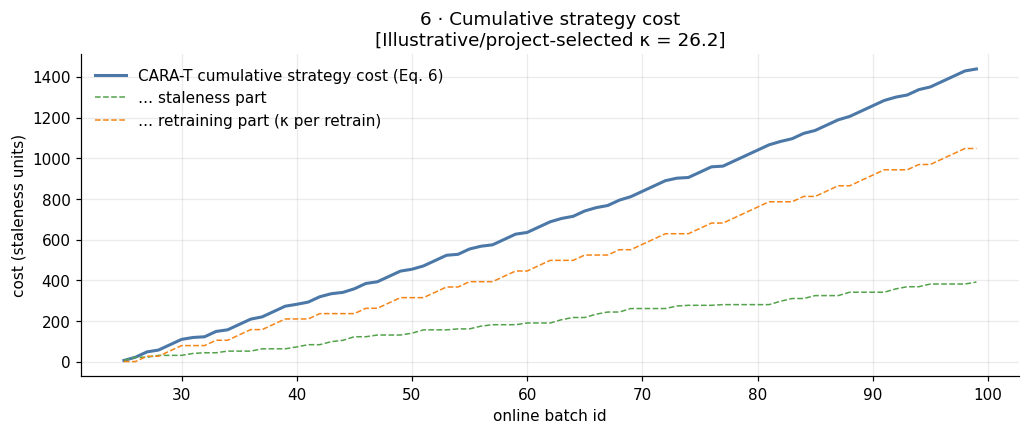

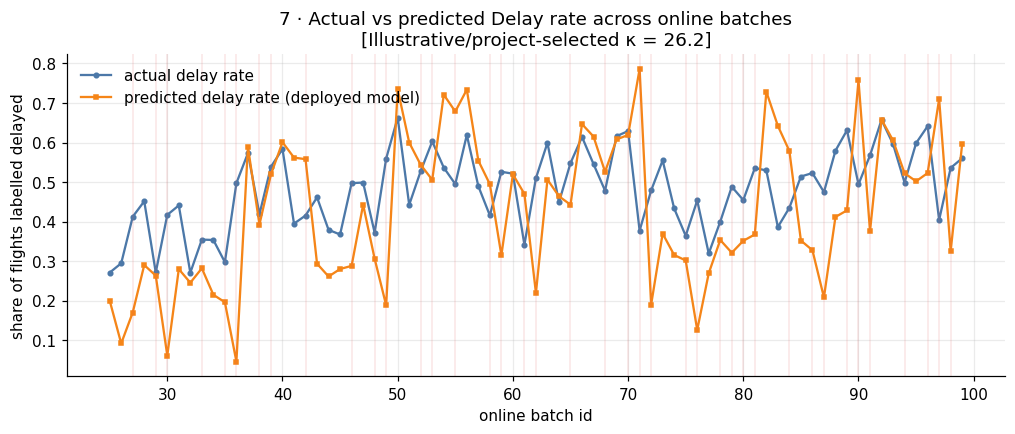

In [40]:
def _T(s):
    return f"{s}\n[{RUN_TAG}]"

def _save(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight"); plt.show()

df = CARA_T_DF
x = df.batch_id.values
ret_b = df.loc[df.retrained, "batch_id"].values
BLUE, ORG, GRN, RED, GRY = "#4C78A8", "#F58518", "#54A24B", "#E45756", "#7F7F7F"

# 1 --- online batch accuracy
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(x, df.accuracy, "-o", ms=3, color=BLUE, label="batch accuracy (deployed model, predicted first)")
ax.plot(x, df.query_accuracy, "-", lw=.9, color=ORG, alpha=.8, label="query accuracy (10% queries, paper metric)")
ax.axhline(V1_HOLDOUT_ACC, color=GRY, ls="--", lw=1, label=f"V1 holdout accuracy (metadata) = {V1_HOLDOUT_ACC:.3f}")
for b in ret_b: ax.axvline(b, color=RED, alpha=.18, lw=1)
ax.set_xlabel("online batch id"); ax.set_ylabel("accuracy"); ax.set_title(_T("1 · Online accuracy per batch (red lines = retrain batches)"))
ax.legend(loc="lower left", ncol=1, fontsize=8); _save(fig, "01_online_accuracy.png")

# 2 --- staleness
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(x, df.staleness, "-o", ms=3, color=GRN)
ax.set_xlabel("online batch id"); ax.set_ylabel("relative staleness Ψ̄ (Eq. 3)")
ax.set_title(_T("2 · Staleness of the deployed model at each online batch")); _save(fig, "02_online_staleness.png")

# 3 --- staleness vs threshold
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(x, df.staleness, "-o", ms=3, color=GRN, label="Ψ̄ of deployed model")
ax.axhline(TAU_STAR, color=RED, ls="--", label=f"CARA-T threshold τ* = {TAU_STAR:.2f}")
ax.scatter(ret_b, df.loc[df.retrained, "staleness"], color=RED, zorder=3, s=30, label="RETRAIN decision (Ψ̄ ≥ τ*)")
ax.set_xlabel("online batch id"); ax.set_ylabel("Ψ̄"); ax.set_title(_T("3 · CARA-T decision rule: staleness against threshold"))
ax.legend(); _save(fig, "03_staleness_vs_threshold.png")

# 4 --- model version vs batch
fig, ax = plt.subplots(figsize=(11, 3.4))
ver_num = df.model_version_before_decision.str[1:].astype(int)
ax.step(x, ver_num, where="post", color=BLUE); ax.scatter(x, ver_num, s=8, color=BLUE)
if int(ver_num.max()) <= 25:
    ax.set_yticks(range(1, int(ver_num.max()) + 1))
ax.set_xlabel("online batch id"); ax.set_ylabel("model version answering the batch")
ax.set_title(_T("4 · Model version used per batch (v1 = supplied model)")); _save(fig, "04_model_version.png")

# 5 --- retraining events
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.eventplot(ret_b, colors=RED, lineoffsets=1, linelengths=.8)
ax.set_xlim(x.min() - 1, x.max() + 1); ax.set_yticks([]); ax.set_xlabel("online batch id")
ax2 = ax.twinx(); ax2.step(x, df.retrained.cumsum(), where="post", color=BLUE); ax2.set_ylabel("cumulative retrains"); ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title(_T(f"5 · Retraining events over the stream ({int(df.retrained.sum())} retrains)")); _save(fig, "05_retraining_events.png")

# 6 --- cumulative strategy cost
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(x, df.cumulative_strategy_cost, color=BLUE, lw=2, label="CARA-T cumulative strategy cost (Eq. 6)")
ax.plot(x, df.assign(c=np.where(df.retrained, 0, df.strategy_cost)).c.cumsum(), color=GRN, lw=1, ls="--", label="… staleness part")
ax.plot(x, df.assign(c=np.where(df.retrained, df.strategy_cost, 0)).c.cumsum(), color=ORG, lw=1, ls="--", label="… retraining part (κ per retrain)")
ax.set_xlabel("online batch id"); ax.set_ylabel("cost (staleness units)"); ax.set_title(_T("6 · Cumulative strategy cost")); ax.legend()
_save(fig, "06_cumulative_strategy_cost.png")

# 7 --- actual vs predicted delay rate
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(x, df.actual_delay_rate, "-o", ms=3, color=BLUE, label="actual delay rate")
ax.plot(x, df.predicted_delay_rate, "-s", ms=3, color=ORG, label="predicted delay rate (deployed model)")
for b in ret_b: ax.axvline(b, color=RED, alpha=.15, lw=1)
ax.set_xlabel("online batch id"); ax.set_ylabel("share of flights labelled delayed")
ax.set_title(_T("7 · Actual vs predicted Delay rate across online batches")); ax.legend(); _save(fig, "07_actual_vs_predicted_delay_rate.png")

## Cell 22 — Strategy comparison at the detailed run's κ (a slice of the sweep)

Same κ, same queries, same Ψ̄ accounting for every row. **Oracle is retrospective** (uses all online labels) and is shown only as a floor. Because this slice is at one κ, treat it as **illustrative (project-selected κ) unless `KAPPA_PRIMARY_ABS` was supplied**; see the sweep for the κ-dependence.

Illustrative/project-selected κ: κ = 26.194   (lower cost is better; Oracle = retrospective, unavailable online)


,strategy,status,run_kind,kappa,total_strategy_cost,strategy_cost_staleness_part,strategy_cost_retraining_part,scpe_vs_oracle_pct,n_retrains,avg_online_accuracy,avg_query_accuracy,avg_online_f1,avg_online_staleness,total_retraining_time_seconds,retraining_cost_proxy_kappa_x_retrains,final_number_of_model_versions
0,CARA-T,"method under study (paper Sec. 5.1, adapted)",Illustrative/project-selected κ,26.1941,"1,438.8515",391.0865,"1,047.7650",5.2113,40,0.6422,0.6410,0.5750,20.0214,16.2148,"1,047.7650",41
1,NR (Always Keep),paper baseline (Sec. 7.4),Illustrative/project-selected κ,26.1941,"2,376.2904","2,376.2904",0.0000,73.7584,0,0.6032,0.6030,0.3420,31.6839,0.0000,0.0000,1
2,Markov,"paper baseline (Sec. 7.4, Eq. 17)",Illustrative/project-selected κ,26.1941,"1,544.7363",706.5243,838.2120,12.9538,32,0.6344,0.6333,0.5434,24.1160,12.9517,838.2120,33
3,Always Retrain,additional project baseline,Illustrative/project-selected κ,26.1941,"1,964.5594",0.0000,"1,964.5594",43.6519,75,0.6402,0.6375,0.5108,21.2310,30.3288,"1,964.5594",76
4,Periodic,project baseline inspired by paper's CARA-P (S...,Illustrative/project-selected κ,26.1941,"2,145.7537","1,910.0066",235.7471,56.9012,9,0.6177,0.6145,0.5408,29.3766,3.5794,235.7471,10
5,Oracle,paper's retrospective lower bound (Sec. 6) - N...,Illustrative/project-selected κ,26.1941,"1,367.5830",634.1475,733.4355,NaN,28,0.6471,0.6448,0.5798,18.7662,11.3859,733.4355,29


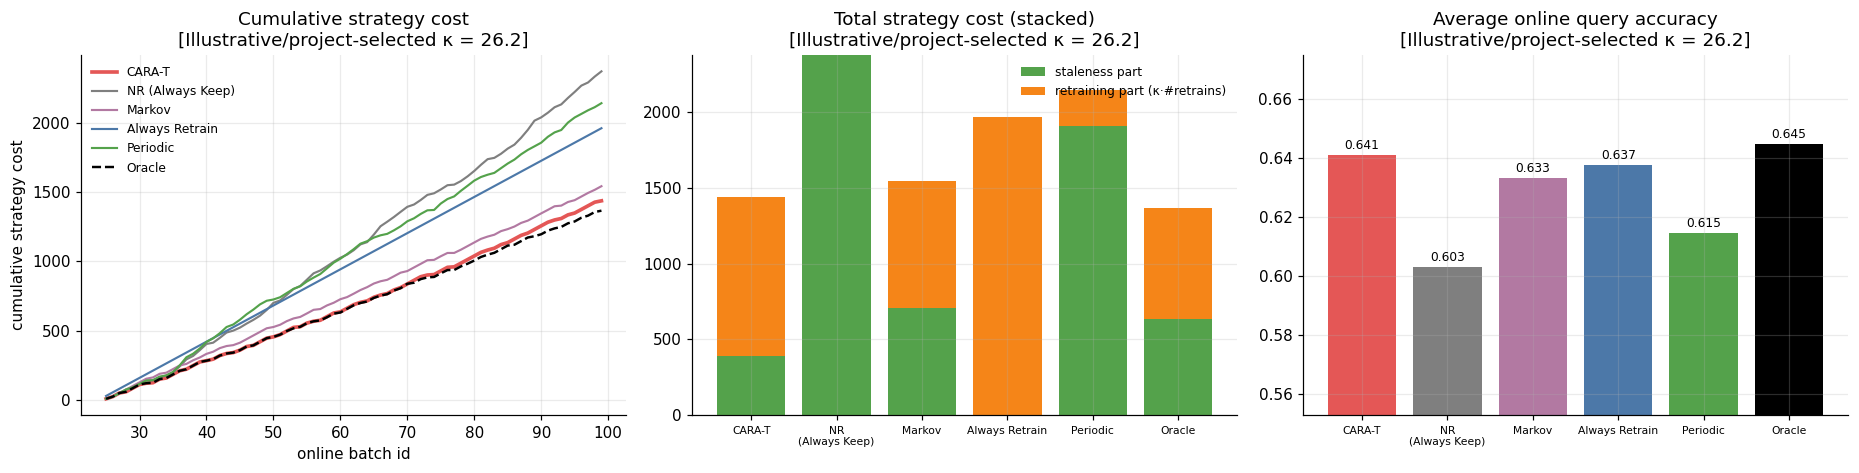

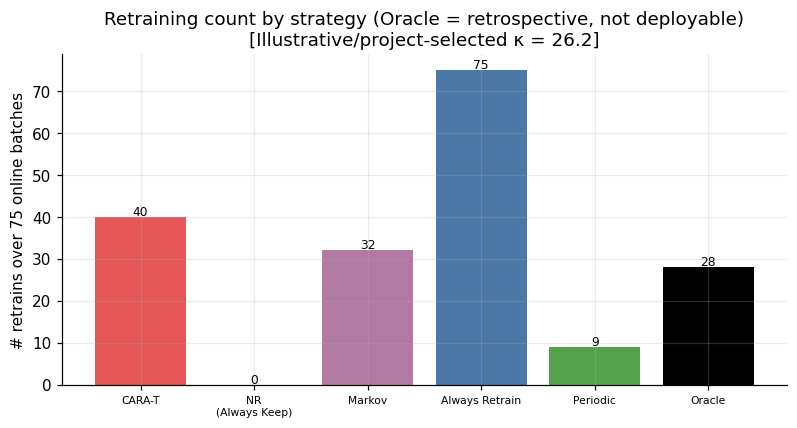

In [41]:
RUNS = {nm: SWEEP_RUNS[(KAPPA_PRIMARY, nm)] for nm in order if (KAPPA_PRIMARY, nm) in SWEEP_RUNS}
RUNS["CARA-T"] = CARA_T_DF                                       # identical to the sweep run (asserted in Cell 19)

rows_ = []
for nm, df_ in RUNS.items():
    r = summarize_run(df_, nm, KAPPA_PRIMARY)
    r["status"] = STRATEGY_STATUS[nm]
    rows_.append(r)
COMPARISON = pd.DataFrame(rows_)
b_ = COMPARISON.loc[COMPARISON.strategy == "Oracle", "total_strategy_cost"]
COMPARISON["scpe_vs_oracle_pct"] = (100 * (b_.iloc[0] - COMPARISON.total_strategy_cost).abs() / abs(b_.iloc[0])
                                    if len(b_) and abs(b_.iloc[0]) > 1e-12 else np.nan)
COMPARISON.loc[COMPARISON.strategy == "Oracle", "scpe_vs_oracle_pct"] = np.nan
COMPARISON["retraining_cost_proxy_kappa_x_retrains"] = COMPARISON["n_retrains"] * KAPPA_PRIMARY
COMPARISON.insert(1, "run_kind", RUN_KIND)
cols = ["strategy", "status", "run_kind", "kappa", "total_strategy_cost", "strategy_cost_staleness_part", "strategy_cost_retraining_part",
        "scpe_vs_oracle_pct", "n_retrains", "avg_online_accuracy", "avg_query_accuracy", "avg_online_f1", "avg_online_staleness",
        "total_retraining_time_seconds", "retraining_cost_proxy_kappa_x_retrains", "final_number_of_model_versions"]
COMPARISON = COMPARISON[cols]
COMPARISON.to_csv(RESULTS_DIR / "baseline_comparison.csv", index=False)
pd.concat([d.assign(run_kind=RUN_KIND) for d in RUNS.values()], ignore_index=True).to_csv(RESULTS_DIR / "baseline_batch_results.csv", index=False)
print(f"{RUN_KIND}: κ = {KAPPA_PRIMARY:.3f}   (lower cost is better; Oracle = retrospective, unavailable online)")
display(COMPARISON)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]
for nm, df_ in RUNS.items():
    ax.plot(df_.batch_id, df_.cumulative_strategy_cost, label=nm, **{k: v for k, v in sty[nm].items() if k in ("color", "lw", "ls")})
ax.set_xlabel("online batch id"); ax.set_ylabel("cumulative strategy cost"); ax.set_title(_T("Cumulative strategy cost")); ax.legend(fontsize=8)
ax = axes[1]; names = COMPARISON.strategy.tolist(); xs = np.arange(len(names))
ax.bar(xs, COMPARISON.strategy_cost_staleness_part, color="#54A24B", label="staleness part")
ax.bar(xs, COMPARISON.strategy_cost_retraining_part, bottom=COMPARISON.strategy_cost_staleness_part, color="#F58518", label="retraining part (κ·#retrains)")
ax.set_xticks(xs); ax.set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=7, rotation=0); ax.set_title(_T("Total strategy cost (stacked)")); ax.legend(fontsize=8)
ax = axes[2]
ax.bar(xs, COMPARISON.avg_query_accuracy, color=[sty[n]["color"] for n in names])
lo, hi = COMPARISON.avg_query_accuracy.min(), COMPARISON.avg_query_accuracy.max()
ax.set_ylim(max(0, lo - 0.05), min(1, hi + 0.03)); ax.set_xticks(xs); ax.set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=7)
for i, v in enumerate(COMPARISON.avg_query_accuracy): ax.text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=8)
ax.set_title(_T("Average online query accuracy"))
plt.tight_layout(); plt.savefig(FIG_DIR / "08_strategy_comparison_single_kappa.png", bbox_inches="tight"); plt.show()
# ---- baseline retraining-count comparison ----
fig, ax = plt.subplots(figsize=(8.5, 3.9))
ax.bar(xs, COMPARISON.n_retrains, color=[sty[n]["color"] for n in names])
for i, v in enumerate(COMPARISON.n_retrains):
    ax.text(i, v + 0.4, str(int(v)), ha="center", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=7)
ax.set_ylabel(f"# retrains over {len(ONLINE_IDS)} online batches")
ax.set_title(_T("Retraining count by strategy (Oracle = retrospective, not deployable)"))
fig.savefig(FIG_DIR / "11_baseline_retraining_counts.png", bbox_inches="tight"); plt.show()


## Cell 23 — Scientific audit: which batches influenced what

In [42]:
def _ids_in_key(key):
    return [int(v) for v in key if isinstance(v, (int, np.integer))]

used_ids = set(MODEL_CACHE.keys())
for key in list(_PSI.keys()) + list(_PRED.keys()) + list(_W.keys()):
    used_ids.update(_ids_in_key(key))
assert not (used_ids & set(HOLDOUT_IDS)), "holdout batches leaked into CARA computations!"
assert all(max(_ids_in_key(k)) <= OFFLINE_IDS[-1] for k in _PSI if k[0] <= OFFLINE_IDS[-1])      # offline cost matrix only touches 0-21

# online decisions of CARA-T and Markov must be exactly reproducible from the recorded staleness and the offline parameters
for kk in KAPPA_GRID:
    c = SWEEP_RUNS[(kk, "CARA-T")];  assert ((c.staleness >= SEL_BY_K[kk]["tau"]) == c.retrained).all()
    m = SWEEP_RUNS[(kk, "Markov")];  assert ((m.staleness >= kk) == m.retrained).all()
    for nm in ("CARA-T", "NR (Always Keep)", "Markov", "Always Retrain", "Periodic", "Oracle"):
        if (kk, nm) in SWEEP_RUNS:
            d = SWEEP_RUNS[(kk, nm)]
            assert (d.model_trained_on_batch < d.batch_id).all(), f"{nm}: a model answered a batch it was trained on"
assert (MODELS_DIR / "v1" / "model_pipeline.joblib").exists() and (MODELS_DIR / "v1" / "metadata.json").exists()

audit = pd.DataFrame([
    ("Model V1 training (previous notebook)", "0-21", "model weights", "n/a"),
    ("CARA offline: cost matrix, tau*(κ), phi*(κ), gamma, similarity encoder, offline Oracle", "0-21", "offline selection", "yes (by design)"),
    ("Holdout 22-24", "22-24", "read-only reproduction of V1 metadata metrics (Cell 7)", "NO"),
    ("Online evaluation (CARA-T, NR, Markov, Always Retrain, Periodic)", "25-99",
     "batch t predicted first, staleness/decision next, training on D_t last; new model serves t+1", "NO (parameters frozen)"),
    ("Retrospective Oracle", "25-99", "uses ALL online labels in advance; reference floor only", "NO (never feeds any decision)"),
], columns=["activity", "batches", "role", "influences CARA parameters?"])
display(audit)
print("Leakage guard: no holdout batch id appears in any model/prediction/kernel cache key.")
print("Every online strategy: the answering model was trained strictly before the batch it predicts.")
print("models/v1 is untouched (copied once from the input artifact; size-checked on every run).")

,activity,batches,role,influences CARA parameters?
0,Model V1 training (previous notebook),0-21,model weights,n/a
1,"CARA offline: cost matrix, tau*(κ), phi*(κ), g...",0-21,offline selection,yes (by design)
2,Holdout 22-24,22-24,read-only reproduction of V1 metadata metrics ...,NO
3,"Online evaluation (CARA-T, NR, Markov, Always ...",25-99,"batch t predicted first, staleness/decision ne...",NO (parameters frozen)
4,Retrospective Oracle,25-99,uses ALL online labels in advance; reference f...,NO (never feeds any decision)


Leakage guard: no holdout batch id appears in any model/prediction/kernel cache key.
Every online strategy: the answering model was trained strictly before the batch it predicts.
models/v1 is untouched (copied once from the input artifact; size-checked on every run).


## Cell 24 — How to read the results

> **This is an adaptation and operationalisation of CARA within an MLOps workflow, not a line-by-line reproduction of the paper.**

* **The κ sweep is the primary result.** κ is an administrator-specified cost in the paper; we have no external cost model. Statements such as "CARA-T is cheaper than X" hold *at the κ values in the sweep* and must be read as a function of κ. The single detailed run uses an **illustrative/project-selected κ** (not paper-defined, not a real-world cost) unless you supplied `KAPPA_PRIMARY_ABS` from an external cost model. The reference scale behind the default grid is a numerical convenience, **not** from the paper and **not** a real-world cost.
* **Baselines.** NR and Markov are paper baselines, Oracle is the paper's retrospective lower bound (unavailable to any online system); Always Retrain and Periodic are additional / paper-inspired project baselines. ADWIN, DDM and CARA-CT are not implemented, so this is not the paper's full comparison.
* **V1 vs retrained models (A2).** Retrained models see one batch (≈5.4k rows), as in the paper; V1 saw 22 batches. A fresher single-batch model can be *less* accurate than V1. τ\* was learned on single-batch models and is applied to V1 at the first online batches.
* **Staleness is relative (Eq. 3).** Ψ̄ subtracts the loss on the model's own training data; a Random Forest has low in-sample loss, so Ψ̄ includes a generalisation-gap component. This is the paper's definition, not altered here.
* **Single seed.** The paper averages five seeds; this notebook uses one (`SEED`).
* **No drift claims** are made.

Output files: `results/kappa_sensitivity.csv` (**primary**: κ, optimal τ\*, offline strategy cost, #retrains, online CARA-T outcome), `kappa_sweep_all_strategies.csv` (every strategy × κ), `cara_t_threshold_selection_by_kappa.csv`, `cara_t_threshold_selection_all_kappa.csv`, `cara_t_threshold_selection.csv`, `cara_t_selected_params.json`, `cara_t_batch_results.csv`, `cara_t_summary.json`, `baseline_comparison.csv`, `baseline_batch_results.csv`, `periodic_phi_selection_all_kappa.csv`, `results/figures/*.png` (incl. `10a/10b/10c` κ plots and `11` retraining counts), `models/v1…vN/{model_pipeline.joblib, metadata.json}`.

## MLOps positioning

This notebook represents the retraining-decision component of the broader MLOps system. Model training, deployment, prediction logging, feedback collection and monitoring are implemented separately. The purpose of this notebook is to learn and evaluate the retraining decision before integrating that logic into the deployed MLOps pipeline.

```
TRAIN → VALIDATE → PACKAGE/VERSION → DEPLOY → PREDICT → LOG → FEEDBACK → MONITOR → [ DECIDE: retrain? (CARA-T, this notebook) ] → RETRAIN → NEW VERSION → REDEPLOY
```

The historical replay of batches 25–99 is a test-then-train simulation of an online stream, not real future flights. Monitoring (*what changed?*) and CARA-T (*should the deployed model be replaced?*) are separate concepts; the Oracle is retrospective and is not part of the deployable pipeline.

In [43]:
print("Output tree:")
for root_ in (RESULTS_DIR, MODELS_DIR):
    for p in sorted(root_.rglob("*")):
        if p.is_file():
            print(f"  {str(p.relative_to(WORK_DIR)):60s} {p.stat().st_size/1024:10.1f} KB")

Output tree:
  results/baseline_batch_results.csv                                177.1 KB
  results/baseline_comparison.csv                                     1.9 KB
  results/cara_t_batch_results.csv                                   31.5 KB
  results/cara_t_selected_params.json                                 1.2 KB
  results/cara_t_summary.json                                         9.7 KB
  results/cara_t_threshold_selection.csv                             36.1 KB
  results/cara_t_threshold_selection_all_kappa.csv                  254.5 KB
  results/cara_t_threshold_selection_by_kappa.csv                     1.5 KB
  results/figures/00_offline_threshold_selection.png                119.0 KB
  results/figures/01_online_accuracy.png                            157.1 KB
  results/figures/02_online_staleness.png                           119.6 KB
  results/figures/03_staleness_vs_threshold.png                     131.1 KB
  results/figures/04_model_version.png                         